# Anggota 4 — Evaluasi bersama, analisis kesalahan, efisiensi, ablasi (T1-B, TXL-PBC)

Notebook ini menjalankan bagian Anggota 4: (1) evaluasi bersama YOLOv8 vs Faster R-CNN dengan **satu alat** (pycocotools) dan **satu format prediksi**, (2) bootstrap CI atas citra, (3) ablasi ambang confidence terhadap galat hitung (**ambang dipilih di val**), (4) analisis kesalahan (galeri, Grad-CAM 4 benar + 4 salah), (5) parameter dan latensi.

**Aturan keras tim:** semua alat dikembangkan pada prediksi **val**. Test dan test_unflagged hanya dipakai **sekali per konfigurasi final** — bagian 9 terkunci (`FINAL_TEST = False`) dan menolak berjalan dua kali.

**Urutan:** jalankan sel dari atas ke bawah. Sel 1–2 menyiapkan lingkungan, sel 3 mengisi skrip, sel 4 = konfigurasi (**isi path bobot**), sel 5–8 semuanya di val. Runtime: GPU (T4) disarankan; tanpa GPU latensi tidak bermakna.

In [14]:
# 1. Lingkungan: Drive, repo tim, dataset (commit yang sama dengan tim)
import os, sys, subprocess, json, time
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

REPO_URL = "https://github.com/a-mint505/tugas_besar_deep_learning_a_kelompok_deep_cheating"
ROOT = Path("/content/repo")
if not ROOT.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
os.chdir(ROOT)
if not Path("data/raw/txl_pbc/TXL-PBC").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/lugan113/TXL-PBC_Dataset", "data/raw/txl_pbc"], check=True)
    subprocess.run(["git", "-C", "data/raw/txl_pbc", "checkout", "-q", "fd9aadd9636d590ce5b25a1936e61bff4e581a48"], check=True)
for f in ["train", "val", "test", "test_unflagged"]:
    assert Path(f"data/processed/coco_clean/{f}.json").exists(), f"anotasi COCO hilang: {f}.json (jalankan pipeline Anggota 1)"
print("cwd:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cwd: /content/repo


In [15]:
%pip install -q ultralytics pycocotools
import ultralytics, torch, torchvision
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (ganti runtime ke GPU)")
# Log tim mencatat ultralytics 8.4.215. Versi lain umumnya bisa memuat best.pt, tetapi catat versi di laporan.

ultralytics 8.4.218 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130
GPU: Tesla T4


## 3. Skrip Anggota 4 (ditulis ke `scripts/` repo)
Empat sel berikut menulis modul yang dipakai notebook ini. File yang sama juga dikirim terpisah agar bisa di-commit ke repo.

In [16]:
%%writefile scripts/eval_shared.py
"""Evaluasi bersama YOLOv8 dan Faster R-CNN (Anggota 4), TXL-PBC, topik T1-B.

Format prediksi tunggal untuk KEDUA model (daftar dict, sama dengan format hasil COCO):
    {"image_id": int, "category_id": 1|2|3, "bbox": [x, y, w, h], "score": float}
bbox = piksel absolut pada citra ASLI. category_id COCO = id YOLO + 1 (1=WBC, 2=RBC, 3=Platelets).
Konversi prediksi YOLO: yolo_to_coco_records(image_id, xyxy, conf, cls0)  (cls0 berbasis 0).

Modul ini sengaja TIDAK memakai torch (bisa diuji di CPU/laptop). Isi:
  - GT: pembaca anotasi COCO (+ buang baris duplikat persis, sama seperti Ultralytics)
  - ModelEval: mAP@0.5, mAP@[.5:.95], AP/recall per kelas, galat hitung (MAE per kelas per citra),
    presisi/recall pada ambang tertentu, hasil per sumber citra
  - bootstrap(): interval kepercayaan persentil atas citra (berpasangan antar model)
  - threshold_curve()/select_threshold()/freeze_thresholds(): ablasi ambang confidence (dipilih di val)
  - append_final_test_row(): tulis ke logs/final_test_results.csv (tanpa menimpa, tanpa duplikat)

Aturan keras tim: kembangkan semua alat pada prediksi VAL. Test/test_unflagged hanya untuk
konfigurasi final, sekali per konfigurasi (CLI menolak split test tanpa --final).

Catatan keterbandingan: AP dihitung dengan pycocotools (interpolasi 101 titik), BUKAN dengan kode
metrik internal Ultralytics, jadi angka YOLO di sini bisa sedikit berbeda dari `model.val()`.
"""
from __future__ import annotations

import argparse
import contextlib
import csv
import io
import json
import math
import time
from collections import Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

CLASS_IDS = {1: "WBC", 2: "RBC", 3: "Platelets"}
CAT_IDS = [1, 2, 3]
PLATELET_ID = 3
KNOWN_SIZES = [(256, 256), (360, 363), (575, 575), (640, 480)]
AREA_LABELS = ["all", "small", "medium", "large"]      # urutan areaRng bawaan pycocotools
REC_THRS = np.linspace(0.0, 1.0, 101)                  # = recThrs bawaan pycocotools
FINAL_TEST_COLS = ["run_id", "test_split", "map50", "map50_95", "ap50_platelet", "mae_wbc", "mae_rbc",
                   "mae_platelet", "bootstrap_ci_platelet", "date", "notes"]


# ------------------------------------------------------------------------------ util kecil
def source_label(w: int, h: int) -> str:
    """Kelompok sumber citra = ukuran citra (sesuai kesepakatan tim)."""
    return f"{int(w)}x{int(h)}" if (int(w), int(h)) in KNOWN_SIZES else "lainnya"


def _nanmean(x) -> float:
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    return float(x.mean()) if x.size else float("nan")


def fmt_ci(lo: float, hi: float, digits: int = 3) -> str:
    if lo is None or hi is None or (isinstance(lo, float) and math.isnan(lo)) or (isinstance(hi, float) and math.isnan(hi)):
        return "NA"
    return f"[{lo:.{digits}f}, {hi:.{digits}f}]"


# ---------------------------------------------------------------- konversi format prediksi
def to_coco_records(image_id, xyxy, scores, category_ids) -> list[dict]:
    """xyxy piksel absolut (x1,y1,x2,y2) -> daftar dict format COCO (bbox xywh)."""
    out = []
    for (x1, y1, x2, y2), s, c in zip(xyxy, scores, category_ids):
        out.append({"image_id": int(image_id), "category_id": int(c),
                    "bbox": [float(x1), float(y1), float(x2) - float(x1), float(y2) - float(y1)],
                    "score": float(s)})
    return out


def yolo_to_coco_records(image_id, xyxy, conf, cls0) -> list[dict]:
    """Prediksi YOLO (kelas berbasis 0) -> format COCO: category_id = cls0 + 1, bbox xywh piksel absolut."""
    return to_coco_records(image_id, xyxy, conf, [int(c) + 1 for c in cls0])


# ------------------------------------------------------------------------------------- GT
class GT:
    """Anotasi COCO (category_id 1-3). dedup=True membuang baris duplikat persis (citra, kelas, kotak),
    seperti yang dilakukan Ultralytics saat memuat label (val: 15 duplikat RBC). Jumlah yang dibuang dicatat."""

    def __init__(self, ann_file, dedup: bool = True):
        from pycocotools.coco import COCO
        self.ann_file = str(ann_file)
        self.name = Path(ann_file).stem
        coco = json.loads(Path(ann_file).read_text())
        self.images = sorted(coco["images"], key=lambda d: d["id"])
        self.img_ids = [im["id"] for im in self.images]
        self.pos = {i: n for n, i in enumerate(self.img_ids)}
        names = {c["id"]: c["name"] for c in coco["categories"]}
        assert names == CLASS_IDS, f"kategori tidak sesuai harapan {CLASS_IDS}: {names}"

        keep, seen = [], set()
        self.n_raw_by_cat = Counter()
        self.n_dup_by_cat = Counter()
        self.n_crowd = 0
        for a in coco["annotations"]:
            assert a["image_id"] in self.pos, f"anotasi merujuk citra tak dikenal: {a['image_id']}"
            if a.get("iscrowd", 0):
                self.n_crowd += 1
                continue
            self.n_raw_by_cat[a["category_id"]] += 1
            key = (a["image_id"], a["category_id"], tuple(round(float(v), 2) for v in a["bbox"]))
            if dedup and key in seen:
                self.n_dup_by_cat[a["category_id"]] += 1
                continue
            seen.add(key)
            keep.append(a)
        self.dedup = dedup
        self.anns = keep
        self.n_dup_removed = int(sum(self.n_dup_by_cat.values()))

        d = {"images": self.images, "annotations": keep, "categories": coco["categories"]}
        with contextlib.redirect_stdout(io.StringIO()):
            c = COCO()
            c.dataset = d
            c.createIndex()
        self.coco = c

        I = len(self.images)
        self.size = np.array([[im["width"], im["height"]] for im in self.images])
        self.src = np.array([source_label(w, h) for w, h in self.size])
        self.n_gt = {cid: np.zeros(I, dtype=int) for cid in CAT_IDS}
        for a in keep:
            self.n_gt[a["category_id"]][self.pos[a["image_id"]]] += 1

    def __len__(self):
        return len(self.images)

    def summary(self) -> pd.DataFrame:
        rows = []
        for s in ["semua"] + sorted(set(self.src)):
            m = np.ones(len(self), bool) if s == "semua" else (self.src == s)
            rows.append({"sumber": s, "n_citra": int(m.sum()),
                         **{f"n_gt_{CLASS_IDS[c]}": int(self.n_gt[c][m].sum()) for c in CAT_IDS},
                         "citra_tanpa_platelet": int((self.n_gt[PLATELET_ID][m] == 0).sum()),
                         "MAE_selalu_0_platelet": float(self.n_gt[PLATELET_ID][m].mean()) if m.any() else float("nan")})
        return pd.DataFrame(rows)


def always_zero_mae(gt: GT, cat: int = PLATELET_ID, idx=None) -> float:
    """MAE hitung per citra bila model selalu memprediksi 0 objek (pembanding yang jujur)."""
    n = gt.n_gt[cat] if idx is None else gt.n_gt[cat][np.asarray(idx)]
    return float(np.mean(n))


# ------------------------------------------------------------------------- validasi prediksi
def clean_predictions(gt: GT, dets: list[dict]) -> tuple[pd.DataFrame, dict]:
    """Periksa format prediksi. Kesalahan format (kunci hilang, image_id/kategori asing, NaN, skor di luar
    [0,1]) -> ValueError. Kotak lebar/tinggi <= 0 dibuang dan dihitung di laporan."""
    if not isinstance(dets, list):
        raise ValueError("prediksi harus berupa list dict")
    if len(dets) == 0:
        raise ValueError("prediksi kosong")
    need = {"image_id", "category_id", "bbox", "score"}
    for d in dets[:1000]:
        miss = need - set(d)
        if miss:
            raise ValueError(f"kunci hilang pada prediksi: {miss}")
    df = pd.DataFrame({"image_id": [d["image_id"] for d in dets],
                       "cat": [d["category_id"] for d in dets],
                       "score": [d["score"] for d in dets]})
    bb = np.asarray([d["bbox"] for d in dets], dtype=float)
    if bb.ndim != 2 or bb.shape[1] != 4:
        raise ValueError(f"bbox harus [x,y,w,h]; bentuk {bb.shape}")
    if not np.isfinite(bb).all() or not np.isfinite(df["score"].to_numpy(float)).all():
        raise ValueError("ada NaN/inf pada bbox atau skor")
    unknown_img = set(df["image_id"]) - set(gt.pos)
    if unknown_img:
        raise ValueError(f"image_id tidak ada di GT {gt.name}: {sorted(unknown_img)[:5]} ...")
    unknown_cat = set(df["cat"]) - set(CAT_IDS)
    if unknown_cat:
        raise ValueError(f"category_id harus 1..3 (YOLO id + 1); ditemukan {sorted(unknown_cat)}")
    if (df["score"] < 0).any() or (df["score"] > 1).any():
        raise ValueError("skor di luar [0,1]")
    df[["x", "y", "w", "h"]] = bb
    bad = (df["w"] <= 0) | (df["h"] <= 0)
    report = {"n_pred_raw": int(len(df)), "n_dropped_nonpositive_box": int(bad.sum())}
    df = df[~bad].copy()
    df["img"] = df["image_id"].map(gt.pos).astype(int)
    df["cat"] = df["cat"].astype(int)
    df = df.reset_index(drop=True)
    report["n_pred"] = int(len(df))
    if len(df) == 0:
        raise ValueError("semua prediksi tidak valid")
    return df, report


# ------------------------------------------------------------------- pencarian folder run/bobot
def find_run_dirs(root, name_glob: str, required_files, max_depth: int = 8):
    """Cari folder run di bawah `root` (rekursif, ikuti tautan/pintasan) yang namanya cocok dengan `name_glob`
    dan berisi SEMUA berkas `required_files` (path relatif, mis. ["weights/best.pt"]).
    Mengembalikan (runs, dups): runs = {nama_run: path_folder}; dups = {nama_run: [path_dipakai, salinan_lain...]}
    untuk nama yang muncul lebih dari sekali (yang dipakai = path terpendek, lalu urutan abjad). Folder yang
    sudah cocok tidak ditelusuri lebih dalam. Folder tempat sampah/.git/__pycache__ dilewati."""
    import fnmatch
    import os
    root = str(root)
    skip = {".Trash", ".Trash-0", ".git", "__pycache__", "site-packages", "node_modules"}
    found: dict[str, list[str]] = {}
    base_depth = root.rstrip(os.sep).count(os.sep)
    for cur, dirs, _files in os.walk(root, followlinks=True):
        depth = cur.rstrip(os.sep).count(os.sep) - base_depth
        dirs[:] = sorted(d for d in dirs if d not in skip)
        if depth >= max_depth:
            dirs[:] = []
        keep = []
        for d in dirs:
            full = os.path.join(cur, d)
            if fnmatch.fnmatch(d, name_glob) and all(os.path.exists(os.path.join(full, f)) for f in required_files):
                found.setdefault(d, []).append(full)
            else:
                keep.append(d)
        dirs[:] = keep
    runs, dups = {}, {}
    for name, paths in found.items():
        paths = sorted(set(paths), key=lambda q: (q.count(os.sep), q))
        runs[name] = paths[0]
        if len(paths) > 1:
            dups[name] = paths
    return runs, dups


# ---------------------------------------------------------------------- AP dari entri per citra
def _accumulate(sc, tp, ig, npig):
    """Salinan logika COCOeval.accumulate untuk satu kelas/area/maxDet. tp, ig: [T, N] bool.
    Mengembalikan (AP per IoU [T], recall per IoU [T]); NaN bila tidak ada GT."""
    T = tp.shape[0]
    if npig == 0:
        return np.full(T, np.nan), np.full(T, np.nan)
    order = np.argsort(-sc, kind="mergesort")
    tp, ig = tp[:, order], ig[:, order]
    tps = np.logical_and(tp, np.logical_not(ig))
    fps = np.logical_and(np.logical_not(tp), np.logical_not(ig))
    tp_sum = np.cumsum(tps, axis=1).astype(float)
    fp_sum = np.cumsum(fps, axis=1).astype(float)
    ap, rec = np.zeros(T), np.zeros(T)
    nd = tp.shape[1]
    for t in range(T):
        tpv, fpv = tp_sum[t], fp_sum[t]
        rc = tpv / npig
        pr = tpv / (fpv + tpv + np.spacing(1))
        rec[t] = rc[-1] if nd else 0.0
        q = np.zeros(len(REC_THRS))
        if nd:
            pr = np.maximum.accumulate(pr[::-1])[::-1]          # envelope presisi (setara loop pycocotools)
            inds = np.searchsorted(rc, REC_THRS, side="left")
            ok = inds < nd
            q[ok] = pr[inds[ok]]
        ap[t] = q.mean()
    return ap, rec


class ModelEval:
    """Satu set prediksi (satu model/seed) terhadap satu GT. Pencocokan COCO (per citra, kelas, IoU)
    dihitung SEKALI oleh pycocotools lalu dipakai ulang untuk subset citra dan bootstrap (pencocokan
    bersifat per citra, jadi resampel citra cukup menyambung ulang entri)."""

    def __init__(self, gt: GT, dets: list[dict], name: str = "model", max_det: int = 100, check: bool = True):
        from pycocotools.cocoeval import COCOeval
        self.gt, self.name, self.max_det = gt, name, max_det
        self.table, self.report = clean_predictions(gt, dets)
        t = self.table
        recs = [{"image_id": int(a), "category_id": int(c), "bbox": [float(x), float(y), float(w), float(h)],
                 "score": float(s)}
                for a, c, x, y, w, h, s in zip(t.image_id, t.cat, t.x, t.y, t.w, t.h, t.score)]
        with contextlib.redirect_stdout(io.StringIO()):
            dt = gt.coco.loadRes(recs)
            ev = COCOeval(gt.coco, dt, "bbox")
            ev.params.imgIds = list(gt.img_ids)
            ev.params.catIds = list(CAT_IDS)
            ev.params.maxDets = [1, 10, max_det]
            ev.evaluate()
        p = ev.params
        K, A, I = len(p.catIds), len(p.areaRng), len(p.imgIds)
        assert list(p.imgIds) == list(gt.img_ids) and list(p.catIds) == CAT_IDS, "urutan id berubah di pycocotools"
        assert len(ev.evalImgs) == K * A * I, "struktur evalImgs pycocotools berbeda dari yang diasumsikan"
        self.T = len(p.iouThrs)
        self.iou_thrs = np.asarray(p.iouThrs)
        self.I = I
        T = self.T
        self.E = []                                        # E[a][k][i] = (skor, tp[T,n], abaikan[T,n], npig)
        for a in range(A):
            Ea = []
            for k in range(K):
                Ek = []
                for i in range(I):
                    e = ev.evalImgs[k * A * I + a * I + i]
                    if e is None:
                        Ek.append((np.empty(0), np.zeros((T, 0), bool), np.zeros((T, 0), bool), 0))
                    else:
                        sc = np.asarray(e["dtScores"], float)[:max_det]
                        n = len(sc)
                        tp = (np.asarray(e["dtMatches"]).reshape(T, -1)[:, :n] > 0)
                        ig = np.asarray(e["dtIgnore"], bool).reshape(T, -1)[:, :n]
                        npig = int(np.count_nonzero(np.asarray(e["gtIgnore"]) == 0))
                        Ek.append((sc, tp, ig, npig))
                Ea.append(Ek)
            self.E.append(Ea)
        # susunan datar (area 'all') untuk presisi/recall pada ambang tertentu
        self._flat = {}
        for k in range(K):
            Ek = self.E[0][k]
            sc = np.concatenate([e[0] for e in Ek]) if I else np.empty(0)
            tp50 = np.concatenate([e[1][0] for e in Ek]) if I else np.empty(0, bool)
            img = np.concatenate([np.full(len(e[0]), i) for i, e in enumerate(Ek)]) if I else np.empty(0, int)
            self._flat[CAT_IDS[k]] = (sc, tp50, img)
        if check:
            self._selfcheck(ev)

    # -- verifikasi terhadap COCOeval.accumulate (menjaga dari perbedaan versi pycocotools)
    def _selfcheck(self, ev):
        with contextlib.redirect_stdout(io.StringIO()):
            ev.accumulate()
        prec = ev.eval["precision"]          # [T, R, K, A, M]
        full = np.arange(self.I)
        for k, cid in enumerate(CAT_IDS):
            ap, _ = self._ap_rec(0, k, full)
            for t in range(self.T):
                ref = prec[t, :, k, 0, -1]
                ref = float(ref[ref > -1].mean()) if (ref > -1).any() else float("nan")
                got = ap[t]
                same = (math.isnan(ref) and math.isnan(got)) or abs(ref - got) < 1e-9
                assert same, f"AP tidak cocok dengan pycocotools (kelas {cid}, IoU idx {t}): {got} vs {ref}"

    def _ap_rec(self, a, k, idx):
        E = self.E[a][k]
        idx = np.asarray(idx, dtype=int)
        if len(idx) == 0:
            return np.full(self.T, np.nan), np.full(self.T, np.nan)
        sc = np.concatenate([E[i][0] for i in idx])
        tp = np.concatenate([E[i][1] for i in idx], axis=1)
        ig = np.concatenate([E[i][2] for i in idx], axis=1)
        npig = int(sum(E[i][3] for i in idx))
        return _accumulate(sc, tp, ig, npig)

    # -------------------------------------------------------------------------- metrik AP
    def ap_metrics(self, idx=None, area: str = "all", classes=CAT_IDS) -> dict:
        idx = np.arange(self.I) if idx is None else np.asarray(idx, dtype=int)
        a = AREA_LABELS.index(area)
        out, ap50s, aps = {}, [], []
        for cid in classes:
            ap, rec = self._ap_rec(a, CAT_IDS.index(cid), idx)
            n = CLASS_IDS[cid]
            out[f"ap50_{n}"], out[f"ap_{n}"], out[f"recall50_{n}"] = float(ap[0]), _nanmean(ap), float(rec[0])
            ap50s.append(ap[0])
            aps.append(_nanmean(ap))
        out["map50"], out["map50_95"] = _nanmean(ap50s), _nanmean(aps)
        return out

    # ----------------------------------------------------------------------- metrik hitung
    def npred(self, cat: int, thr: float, idx=None) -> np.ndarray:
        """Jumlah prediksi kelas `cat` dengan skor >= thr per citra (urutan citra = gt.img_ids)."""
        t = self.table
        m = (t.cat.to_numpy() == cat) & (t.score.to_numpy() >= thr)
        n = np.bincount(t.img.to_numpy()[m], minlength=self.I)
        return n if idx is None else n[np.asarray(idx, dtype=int)]

    def npred_matrix(self, cat: int, grid) -> np.ndarray:
        """[G, I]: jumlah prediksi per citra untuk tiap ambang pada grid."""
        t = self.table
        c = t.cat.to_numpy() == cat
        sc, im = t.score.to_numpy()[c], t.img.to_numpy()[c]
        return np.stack([np.bincount(im[sc >= g], minlength=self.I) for g in grid])

    def count_metrics(self, thr, idx=None) -> dict:
        """MAE hitung per citra (|prediksi - GT|) per kelas; thr bisa skalar atau {kelas: ambang}."""
        out = {}
        for cid in CAT_IDS:
            th = thr[cid] if isinstance(thr, dict) else thr
            ngt = self.gt.n_gt[cid] if idx is None else self.gt.n_gt[cid][np.asarray(idx, dtype=int)]
            npd = self.npred(cid, th, idx)
            n = CLASS_IDS[cid]
            if len(ngt) == 0:
                out[f"mae_{n}"] = out[f"bias_{n}"] = out[f"exact_{n}"] = float("nan")
                continue
            err = np.abs(npd - ngt)
            pos = ngt > 0
            out[f"mae_{n}"] = float(np.mean(err))
            out[f"bias_{n}"] = float(np.mean(npd - ngt))           # >0: kelebihan prediksi (FP > FN)
            out[f"exact_{n}"] = float(np.mean(npd == ngt))         # proporsi citra dengan hitungan tepat
            # MAPE per citra TIDAK terdefinisi bila GT = 0: dihitung hanya pada citra dengan GT > 0.
            out[f"mape_{n}"] = float(np.mean(err[pos] / ngt[pos]) * 100) if pos.any() else float("nan")
            out[f"n_img_gt_{n}"] = int(pos.sum())                  # jumlah citra yang masuk MAPE
            # WAPE = sum|galat| / sum GT (agregat; tetap terdefinisi walau banyak citra tanpa objek)
            out[f"wape_{n}"] = float(err.sum() / ngt.sum() * 100) if ngt.sum() > 0 else float("nan")
        return out

    def recall_img(self, cat: int, thr: float, idx=None) -> tuple[float, float]:
        """Recall per citra (TP/GT pada IoU 0.5, skor >= thr) dirata-ratakan atas citra dengan GT > 0, dan
        proporsi citra yang SEMUA objeknya ditemukan. (nan, nan) bila tak ada citra dengan GT > 0."""
        sc, tp50, img = self._flat[cat]
        m = sc >= thr
        tpc = np.bincount(img[m][tp50[m]], minlength=self.I)
        ids = np.arange(self.I) if idx is None else np.asarray(idx, dtype=int)
        ng, tp = self.gt.n_gt[cat][ids], tpc[ids]
        pos = ng > 0
        if not pos.any():
            return float("nan"), float("nan")
        return float(np.mean(tp[pos] / ng[pos])), float(np.mean(tp[pos] == ng[pos]))

    def prf(self, cat: int, thr: float, idx=None) -> dict:
        """Presisi/recall/F1 pada IoU 0.5 untuk prediksi dengan skor >= thr (dari pencocokan COCO)."""
        sc, tp50, img = self._flat[cat]
        w = np.ones(self.I) if idx is None else np.bincount(np.asarray(idx, dtype=int), minlength=self.I).astype(float)
        m = sc >= thr
        wt = w[img[m]]
        tp = float(np.sum(wt * tp50[m]))
        fp = float(np.sum(wt * ~tp50[m]))
        ngt = float(np.sum(w * self.gt.n_gt[cat]))
        prec = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
        rec = tp / ngt if ngt > 0 else float("nan")
        f1 = 2 * prec * rec / (prec + rec) if (prec == prec and rec == rec and (prec + rec) > 0) else float("nan")
        return {"precision": prec, "recall": rec, "f1": f1, "tp": tp, "fp": fp, "n_gt": ngt}

    def summary(self, thr, idx=None) -> dict:
        """Satu baris ringkas: AP total/per kelas, AP platelet kecil (COCO small), galat hitung, P/R platelet."""
        out = {"n_citra": self.I if idx is None else int(len(idx)), "thr": thr if not isinstance(thr, dict) else json.dumps(thr)}
        out.update(self.ap_metrics(idx))
        sm = self.ap_metrics(idx, area="small", classes=[PLATELET_ID])
        out["ap_small_Platelets_cocoSmall"] = sm["ap_Platelets"]     # small COCO = area < 32^2 px pada citra asli
        for ar in ("small", "medium", "large"):
            am = self.ap_metrics(idx, area=ar)                       # AP[.5:.95] rerata kelas yang punya GT di rentang itu
            out[f"AP_{ar}_semua_kelas"] = am["map50_95"]
            out[f"AP_{ar}_Platelets"] = am["ap_Platelets"]
        out.update(self.count_metrics(thr, idx))
        th = thr[PLATELET_ID] if isinstance(thr, dict) else thr
        rm, rf = self.recall_img(PLATELET_ID, th, idx)
        out["recall_img_Platelets"], out["recall_img_penuh_Platelets"] = rm, rf
        pr = self.prf(PLATELET_ID, th, idx)
        out.update({"prec_Platelets": pr["precision"], "rec_Platelets": pr["recall"], "f1_Platelets": pr["f1"],
                    "n_pred_Platelets": int(self.npred(PLATELET_ID, th, idx).sum()),
                    "n_gt_Platelets": int((self.gt.n_gt[PLATELET_ID] if idx is None else self.gt.n_gt[PLATELET_ID][np.asarray(idx, dtype=int)]).sum()),
                    "mae_Platelets_selalu0": always_zero_mae(self.gt, PLATELET_ID, idx)})
        return out

    def per_source(self, thr, min_gt_platelet: int = 10) -> pd.DataFrame:
        """Hasil per sumber citra (= ukuran citra). `andal=False` bila platelet GT di sumber itu < min_gt_platelet."""
        rows = []
        th = thr[PLATELET_ID] if isinstance(thr, dict) else thr
        for s in sorted(set(self.gt.src)):
            idx = np.flatnonzero(self.gt.src == s)
            r = {"sumber": s, **self.summary(thr, idx)}
            ngt = self.gt.n_gt[PLATELET_ID][idx]
            npd = self.npred(PLATELET_ID, th, idx)
            r["n_pred_Platelets_di_citra_tanpa_GT_platelet"] = int(npd[ngt == 0].sum())
            r["andal"] = bool(r["n_gt_Platelets"] >= min_gt_platelet)
            rows.append(r)
        return pd.DataFrame(rows)


# ---------------------------------------------------------------------------------- bootstrap
_BOOT_DEFAULT = ("ap50_Platelets", "ap_Platelets", "ap_small_Platelets", "mae_Platelets", "mape_Platelets",
                 "wape_Platelets", "recall_img_Platelets", "map50", "map50_95")


def _boot_draws(gt: GT, B: int, seed: int, strata: str | None) -> np.ndarray:
    rng = np.random.default_rng(seed)
    I = len(gt)
    if strata is None:
        return rng.integers(0, I, size=(B, I))
    if strata != "source":
        raise ValueError("strata harus None atau 'source'")
    groups = [np.flatnonzero(gt.src == s) for s in sorted(set(gt.src))]
    return np.stack([np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups]) for _ in range(B)])


def _one_replicate(me: ModelEval, idx, thr, names) -> dict:
    """Nama metrik yang didukung: map50, map50_95, ap50_/ap_/recall50_<Kelas>, ap_small_Platelets,
    mae_/mape_/wape_<Kelas>, recall_img_Platelets."""
    out = {}
    ap_names = [n for n in names if n.split("_")[0] in ("map50", "map50", "ap50", "recall50") or n in ("map50_95",)
                or (n.startswith("ap_") and not n.startswith("ap_small"))]
    if ap_names:
        need_all = any(n in ("map50", "map50_95") for n in ap_names)
        ap = me.ap_metrics(idx, classes=CAT_IDS if need_all else [PLATELET_ID])
        for n in ap_names:
            out[n] = ap[n]
    for n in names:
        if n == "ap_small_Platelets":
            out[n] = me.ap_metrics(idx, area="small", classes=[PLATELET_ID])["ap_Platelets"]
        elif n == "recall_img_Platelets":
            th = thr[PLATELET_ID] if isinstance(thr, dict) else thr
            out[n] = me.recall_img(PLATELET_ID, th, idx)[0]
        elif n.split("_")[0] in ("mae", "mape", "wape"):
            kind, cname = n.split("_", 1)
            cid = next(c for c, nm in CLASS_IDS.items() if nm == cname)
            th = thr[cid] if isinstance(thr, dict) else thr
            cm = me.count_metrics({c: (th if c == cid else 0.5) for c in CAT_IDS}, idx)
            out[n] = cm[n]
        elif n not in out:
            raise ValueError(f"metrik bootstrap tidak dikenal: {n}")
    return out


def bootstrap(models: dict, gt: GT, thr, B: int = 1000, seed: int = 2024, strata: str | None = None,
              metrics=_BOOT_DEFAULT, alpha: float = 0.05, pairs: bool = True):
    """Bootstrap persentil atas CITRA (dengan pengembalian). `models`: {nama: ModelEval | [ModelEval, ...]}.
    Bila satu model punya beberapa seed, metrik tiap resampel = rerata antar seed (CI untuk rerata seed,
    hanya mengukur ketidakpastian pemilihan citra uji). Citra yang sama dipakai semua model pada tiap resampel,
    sehingga selisih antar model (berpasangan) valid.

    Mengembalikan (ringkasan: DataFrame, sampel: DataFrame [B x (model|metrik)])."""
    models = {k: (v if isinstance(v, (list, tuple)) else [v]) for k, v in models.items()}
    metrics = tuple(metrics)
    # thr: skalar, {id_kelas: ambang}, ATAU {nama_model: ambang_atau_dict_kelas} (ambang beda per model)
    per_model = isinstance(thr, dict) and len(thr) > 0 and all(isinstance(k, str) for k in thr)
    if per_model:
        missing = set(models) - set(thr)
        if missing:
            raise ValueError(f"ambang tidak ada untuk model: {missing}")
    thr_of = (lambda k: thr[k]) if per_model else (lambda k: thr)
    I = len(gt)
    draws = _boot_draws(gt, B, seed, strata)
    full = np.arange(I)

    def agg(mlist, idx, k):
        reps = [_one_replicate(me, idx, thr_of(k), metrics) for me in mlist]
        return {n: _nanmean([r[n] for r in reps]) if not all(math.isnan(r[n]) for r in reps) else float("nan") for n in metrics}

    point = {k: agg(v, full, k) for k, v in models.items()}
    samples = {f"{k}|{n}": np.full(B, np.nan) for k in models for n in metrics}
    for b in range(B):
        idx = draws[b]
        for k, v in models.items():
            r = agg(v, idx, k)
            for n in metrics:
                samples[f"{k}|{n}"][b] = r[n]
    samp = pd.DataFrame(samples)

    lo_q, hi_q = 100 * alpha / 2, 100 * (1 - alpha / 2)
    rows = []
    for k in models:
        for n in metrics:
            x = samp[f"{k}|{n}"].to_numpy()
            xv = x[~np.isnan(x)]
            rows.append({"model": k, "metrik": n, "n_seed": len(models[k]), "titik": point[k][n],
                         "boot_mean": float(xv.mean()) if xv.size else float("nan"),
                         "ci_lo": float(np.percentile(xv, lo_q)) if xv.size else float("nan"),
                         "ci_hi": float(np.percentile(xv, hi_q)) if xv.size else float("nan"),
                         "n_valid": int(xv.size), "B": B})
    if pairs and len(models) > 1:
        for ka, kb in combinations(models, 2):
            for n in metrics:
                d = (samp[f"{ka}|{n}"] - samp[f"{kb}|{n}"]).to_numpy()
                dv = d[~np.isnan(d)]
                rows.append({"model": f"{ka} - {kb}", "metrik": n, "n_seed": np.nan,
                             "titik": point[ka][n] - point[kb][n],
                             "boot_mean": float(dv.mean()) if dv.size else float("nan"),
                             "ci_lo": float(np.percentile(dv, lo_q)) if dv.size else float("nan"),
                             "ci_hi": float(np.percentile(dv, hi_q)) if dv.size else float("nan"),
                             "n_valid": int(dv.size), "B": B,
                             "frac_selisih_positif": float(np.mean(dv > 0)) if dv.size else float("nan")})
    return pd.DataFrame(rows), samp


# ------------------------------------------------------------------- ablasi ambang confidence
def default_grid() -> list[float]:
    """Grid ambang (ditetapkan SEBELUM melihat kurva): 0.01, 0.02, 0.05, lalu 0.10 s.d. 0.95 langkah 0.05."""
    g = [0.01, 0.02, 0.05] + [round(float(x), 2) for x in np.arange(0.10, 0.951, 0.05)]
    return sorted(set(g))


def threshold_curve(seed_evals: list[ModelEval], grid=None) -> pd.DataFrame:
    """Kurva galat hitung vs ambang (SATU ambang global untuk semua kelas), rerata antar seed.
    AP/mAP tidak bergantung pada ambang (dihitung dari seluruh peringkat skor), jadi tidak ada di sini."""
    grid = default_grid() if grid is None else list(grid)
    rows = []
    for g in grid:
        per_seed = [me.count_metrics(g) for me in seed_evals]
        prf = [me.prf(PLATELET_ID, g) for me in seed_evals]
        r = {"thr": g}
        for n in CLASS_IDS.values():
            r[f"mae_{n}"] = _nanmean([p[f"mae_{n}"] for p in per_seed])
            r[f"bias_{n}"] = _nanmean([p[f"bias_{n}"] for p in per_seed])
        r["mae_Platelets_sd_antar_seed"] = float(np.std([p["mae_Platelets"] for p in per_seed], ddof=1)) if len(per_seed) > 1 else float("nan")
        r["prec_Platelets"] = _nanmean([p["precision"] for p in prf])
        r["rec_Platelets"] = _nanmean([p["recall"] for p in prf])
        r["f1_Platelets"] = _nanmean([p["f1"] for p in prf])
        r["n_pred_Platelets"] = float(np.mean([me.npred(PLATELET_ID, g).sum() for me in seed_evals]))
        rows.append(r)
    return pd.DataFrame(rows)


def select_threshold(seed_evals: list[ModelEval], grid=None, B: int = 1000, seed: int = 0,
                     cat: int = PLATELET_ID, strata: str | None = None) -> dict:
    """Pilih ambang pada VAL dengan aturan yang ditetapkan di muka ('plateau pusat, 1-SE'):
      1. MAE_hitung(thr) kelas `cat` = rerata antar seed dari rerata |prediksi - GT| per citra val.
      2. SE = simpangan baku MAE di ambang minimum, dari bootstrap atas citra val.
      3. Plateau = rentang ambang bersebelahan dengan MAE <= MAE_min + SE yang memuat ambang minimum.
      4. thr* = ambang di TENGAH plateau (median indeks; meredam derau pilihan argmin).
    Juga dilaporkan argmin murni dan frekuensi argmin pada resampel (stabilitas pilihan)."""
    grid = default_grid() if grid is None else list(grid)
    gt = seed_evals[0].gt
    ngt = gt.n_gt[cat]
    err = np.mean([np.abs(me.npred_matrix(cat, grid) - ngt[None, :]) for me in seed_evals], axis=0)   # [G, I]
    mae = err.mean(axis=1)
    mins = np.flatnonzero(mae <= mae.min() + 1e-12)
    i_min = int(mins[(len(mins) - 1) // 2])
    draws = _boot_draws(gt, B, seed, strata)
    boot = np.stack([err[:, d].mean(axis=1) for d in draws])                  # [B, G]
    se = float(boot[:, i_min].std(ddof=1)) if B > 1 else float("nan")
    ok = mae <= mae[i_min] + se
    lo = hi = i_min
    while lo - 1 >= 0 and ok[lo - 1]:
        lo -= 1
    while hi + 1 < len(grid) and ok[hi + 1]:
        hi += 1
    run = list(range(lo, hi + 1))
    i_star = run[(len(run) - 1) // 2]
    argmins = boot.argmin(axis=1)
    freq = {grid[g]: float(np.mean(argmins == g)) for g in range(len(grid)) if np.any(argmins == g)}
    return {"rule": "plateau_pusat_1SE_pada_val", "cat": cat, "grid": grid, "n_seed": len(seed_evals),
            "thr_star": float(grid[i_star]), "thr_argmin": float(grid[i_min]),
            "plateau": [float(grid[g]) for g in run], "se_at_argmin": se,
            "mae_val": [float(x) for x in mae],
            "ci_lo": [float(x) for x in np.percentile(boot, 2.5, axis=0)],
            "ci_hi": [float(x) for x in np.percentile(boot, 97.5, axis=0)],
            "mae_val_at_thr_star": float(mae[i_star]), "mae_val_selalu0": always_zero_mae(gt, cat),
            "argmin_freq_bootstrap": freq, "B": B, "seed": seed, "strata": strata}


def freeze_thresholds(path, key: str, result: dict, meta: dict | None = None, force: bool = False) -> dict:
    """Bekukan ambang terpilih (dari val) ke JSON. Menolak menimpa kunci yang sudah ada kecuali force=True.
    Berkas ini adalah satu-satunya sumber ambang untuk evaluasi test."""
    path = Path(path)
    data = json.loads(path.read_text()) if path.exists() else {}
    if key in data and not force:
        raise FileExistsError(f"ambang '{key}' sudah dibekukan di {path}; gunakan force=True hanya bila tim setuju")
    data[key] = {"thr": result["thr_star"], "thr_argmin": result["thr_argmin"], "rule": result["rule"],
                 "plateau": result["plateau"], "grid": result["grid"], "cat": result["cat"],
                 "n_seed": result["n_seed"], "mae_val_at_thr": result["mae_val_at_thr_star"],
                 "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), **(meta or {})}
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, indent=2))
    return data[key]


def load_frozen(path, key: str) -> float:
    data = json.loads(Path(path).read_text())
    if key not in data:
        raise KeyError(f"ambang '{key}' belum dibekukan di {path}. Jalankan ablasi di VAL dulu.")
    return float(data[key]["thr"])


# ------------------------------------------------------------- pencatatan hasil akhir (test)
def append_final_test_row(csv_path, row: dict) -> None:
    """Tambah satu baris ke logs/final_test_results.csv. Menolak duplikat (run_id, test_split) agar test
    benar-benar dipakai sekali per konfigurasi. Aman terhadap berkas yang barisnya tidak diakhiri newline."""
    csv_path = Path(csv_path)
    unknown = set(row) - set(FINAL_TEST_COLS)
    assert not unknown, f"kolom tidak dikenal: {unknown}"
    row = {c: row.get(c, "") for c in FINAL_TEST_COLS}
    if csv_path.exists() and csv_path.stat().st_size > 0:
        raw = csv_path.read_bytes().decode("utf-8")
        header = next(csv.reader(io.StringIO(raw)))
        assert header == FINAL_TEST_COLS, f"header berbeda dari yang diharapkan: {header}"
        for r in csv.DictReader(io.StringIO(raw)):
            if r["run_id"] == row["run_id"] and r["test_split"] == row["test_split"]:
                raise ValueError(f"({row['run_id']}, {row['test_split']}) sudah ada di {csv_path}: test hanya sekali per konfigurasi")
        with open(csv_path, "a", newline="", encoding="utf-8") as f:
            if not raw.endswith("\n"):
                f.write("\n")
            csv.DictWriter(f, fieldnames=FINAL_TEST_COLS, lineterminator="\n").writerow(row)
    else:
        csv_path.parent.mkdir(parents=True, exist_ok=True)
        with open(csv_path, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=FINAL_TEST_COLS, lineterminator="\n")
            w.writeheader()
            w.writerow(row)


def final_test_already_done(csv_path, run_id: str, test_split: str) -> bool:
    p = Path(csv_path)
    if not p.exists() or p.stat().st_size == 0:
        return False
    with open(p, newline="", encoding="utf-8") as f:
        return any(r["run_id"] == run_id and r["test_split"] == test_split for r in csv.DictReader(f))


# ----------------------------------------------------------------------------------------- CLI
def main():
    ap = argparse.ArgumentParser(description="Evaluasi bersama; prediksi dalam format COCO (lihat docstring modul).")
    ap.add_argument("--gt", required=True, help="mis. data/processed/coco_clean/val.json")
    ap.add_argument("--pred", nargs="+", required=True, help="satu/lebih berkas prediksi JSON")
    ap.add_argument("--names", default=None, help="nama model dipisah koma, urut sesuai --pred")
    ap.add_argument("--thr", type=float, default=0.5, help="ambang confidence untuk galat hitung dan P/R")
    ap.add_argument("--bootstrap", type=int, default=1000, help="jumlah resampel (0 = lewati)")
    ap.add_argument("--no-dedup", action="store_true", help="jangan buang baris GT duplikat persis")
    ap.add_argument("--out", default=None, help="folder keluaran CSV")
    ap.add_argument("--final", action="store_true", help="WAJIB untuk split test/test_unflagged (penggunaan sekali)")
    a = ap.parse_args()

    stem = Path(a.gt).stem
    if stem.startswith("test") and not a.final:
        raise SystemExit("Split test/test_unflagged hanya untuk konfigurasi final: tambahkan --final bila memang itu.")
    gt = GT(a.gt, dedup=not a.no_dedup)
    print(f"GT {gt.name}: {len(gt)} citra; duplikat dibuang: {dict(gt.n_dup_by_cat)}; per kelas: "
          f"{ {CLASS_IDS[c]: int(gt.n_gt[c].sum()) for c in CAT_IDS} }")
    print(gt.summary().to_string(index=False))
    names = a.names.split(",") if a.names else [Path(p).stem for p in a.pred]
    assert len(names) == len(a.pred), "jumlah --names harus sama dengan --pred"
    evals = {n: ModelEval(gt, json.loads(Path(p).read_text()), name=n) for n, p in zip(names, a.pred)}
    summ = pd.DataFrame([{"model": n, **me.summary(a.thr)} for n, me in evals.items()])
    print(summ.round(4).T.to_string())
    out = Path(a.out) if a.out else None
    if out:
        out.mkdir(parents=True, exist_ok=True)
        summ.to_csv(out / "summary.csv", index=False)
    for n, me in evals.items():
        ps = me.per_source(a.thr)
        print(f"\nPer sumber citra: {n}")
        print(ps[["sumber", "n_citra", "n_gt_Platelets", "ap50_Platelets", "mae_Platelets", "mae_Platelets_selalu0",
                  "n_pred_Platelets_di_citra_tanpa_GT_platelet", "andal"]].round(4).to_string(index=False))
        if out:
            ps.to_csv(out / f"per_source_{n}.csv", index=False)
    if a.bootstrap > 0:
        res, _ = bootstrap(evals, gt, a.thr, B=a.bootstrap)
        print("\nBootstrap atas citra (CI 95% persentil):")
        print(res.round(4).to_string(index=False))
        if out:
            res.to_csv(out / "bootstrap.csv", index=False)


if __name__ == "__main__":
    main()

Overwriting scripts/eval_shared.py


In [17]:
%%writefile scripts/error_analysis.py
"""Analisis kesalahan detektor (Anggota 4): taksonomi FP/FN sederhana + galeri contoh salah.

Tanpa torch. Memakai GT dan ModelEval dari scripts/eval_shared.py.

Taksonomi (ala TIDE tetapi SEDERHANA dan buatan sendiri; BUKAN toolbox TIDE, Bolya dkk. 2020), pada ambang
confidence `thr` dan IoU 0.5 (pencocokan serakah per kelas menurut skor, seperti COCO):
  TP                      : prediksi cocok dengan GT sekelas (IoU >= 0.5).
  FP / duplikat           : IoU >= 0.5 dengan GT sekelas yang sudah dipakai prediksi lain.
  FP / salah_kelas        : IoU >= 0.5 dengan GT kelas lain.
  FP / lokalisasi         : IoU 0.1..0.5 dengan GT sekelas (kotak ada, tetapi kurang pas).
  FP / lainnya            : IoU 0.1..0.5 dengan GT kelas lain saja.
  FP / latar_belakang     : IoU < 0.1 dengan semua GT (bisa saja platelet asli yang tidak dianotasi:
                            periksa visual, terutama di sumber 575x575).
  FN / skor_rendah        : ada prediksi sekelas IoU >= 0.5 tetapi skornya < thr (korban ambang).
  FN / salah_kelas        : ada prediksi kelas lain (skor >= thr) IoU >= 0.5.
  FN / tumpang_tindih     : prediksi sekelas IoU >= 0.5 ada, tetapi sudah dipakai GT lain (sel bertumpuk).
  FN / lokalisasi         : prediksi sekelas (skor >= thr) IoU 0.1..0.5.
  FN / terlewat           : tidak ada prediksi yang relevan.
Urutan pemeriksaan = urutan daftar di atas (kondisi pertama yang terpenuhi menang).
"""
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

from eval_shared import CLASS_IDS, PLATELET_ID, GT, ModelEval


def _xyxy(b) -> np.ndarray:
    b = np.asarray(b, float).reshape(-1, 4)
    return np.stack([b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]], axis=1)


def _iou(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    bb = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + bb[None, :] - inter + 1e-12)


def size_bin(area: float) -> str:
    """Definisi COCO pada piksel citra asli: small < 32^2, medium < 96^2, large selebihnya."""
    return "kecil" if area < 32 ** 2 else ("sedang" if area < 96 ** 2 else "besar")


def classify_errors(me: ModelEval, thr: float, iou_thr: float = 0.5, bg_iou: float = 0.1) -> pd.DataFrame:
    """Satu baris per TP/FP/FN. Kotak fokus (x,y,w,h): prediksi untuk TP/FP, GT untuk FN."""
    gt, tab = me.gt, me.table
    by_img_g: dict[int, list] = {}
    for a in gt.anns:
        by_img_g.setdefault(gt.pos[a["image_id"]], []).append(a)
    tab_sorted = tab.sort_values("score", ascending=False, kind="mergesort")
    by_img_d = {i: g for i, g in tab_sorted.groupby("img")}
    rows = []
    for i in range(len(gt)):
        G = by_img_g.get(i, [])
        Gb = _xyxy([a["bbox"] for a in G]) if G else np.zeros((0, 4))
        Gc = np.array([a["category_id"] for a in G], int)
        Dt = by_img_d.get(i)
        if Dt is None:
            Dt = tab_sorted.iloc[0:0]
        Db = _xyxy(Dt[["x", "y", "w", "h"]].to_numpy()) if len(Dt) else np.zeros((0, 4))
        Dc, Ds = Dt["cat"].to_numpy(int), Dt["score"].to_numpy(float)
        hi = Ds >= thr
        iou = _iou(Db, Gb)                                                   # [nd, ng]
        gmatch = np.full(len(G), -1)
        dmatch = np.full(len(Dt), -1)
        for d in np.flatnonzero(hi):
            if len(G) == 0:
                break
            cand = (Gc == Dc[d]) & (gmatch < 0)
            if cand.any():
                v = np.where(cand, iou[d], -1.0)
                j = int(v.argmax())
                if v[j] >= iou_thr:
                    gmatch[j], dmatch[d] = d, j
        base = {"img": i, "image_id": gt.img_ids[i], "file_name": gt.images[i]["file_name"], "sumber": gt.src[i]}

        def _row(kind, sub, cat, score, box, gt_box=None, iou_v=np.nan):
            x, y, w, h = box
            r = dict(base, kind=kind, subtype=sub, cat=int(cat), kelas=CLASS_IDS[int(cat)], score=score,
                     x=float(x), y=float(y), w=float(w), h=float(h), ukuran=size_bin(w * h), iou=float(iou_v))
            if gt_box is not None:
                r.update(gx=float(gt_box[0]), gy=float(gt_box[1]), gw=float(gt_box[2]), gh=float(gt_box[3]))
            return r

        for d in np.flatnonzero(hi):
            box = Dt[["x", "y", "w", "h"]].to_numpy()[d]
            if dmatch[d] >= 0:
                j = dmatch[d]
                rows.append(_row("TP", "benar", Dc[d], Ds[d], box, G[j]["bbox"], iou[d, j]))
                continue
            io = iou[d] if len(G) else np.zeros(0)
            same = Gc == Dc[d]
            if len(G) and (io[same] >= iou_thr).any():
                sub = "duplikat"
            elif len(G) and (io[~same] >= iou_thr).any():
                sub = "salah_kelas"
            elif len(G) and (io[same] >= bg_iou).any():
                sub = "lokalisasi"
            elif len(G) and (io >= bg_iou).any():
                sub = "lainnya"
            else:
                sub = "latar_belakang"
            rows.append(_row("FP", sub, Dc[d], Ds[d], box, iou_v=(io.max() if len(io) else np.nan)))
        for j in np.flatnonzero(gmatch < 0):
            io = iou[:, j] if len(Dt) else np.zeros(0)
            same = Dc == Gc[j]
            if len(Dt) and (same & ~hi & (io >= iou_thr)).any():
                sub = "skor_rendah"
            elif len(Dt) and (~same & hi & (io >= iou_thr)).any():
                sub = "salah_kelas"
            elif len(Dt) and (same & hi & (io >= iou_thr)).any():
                sub = "tumpang_tindih"
            elif len(Dt) and (same & hi & (io >= bg_iou)).any():
                sub = "lokalisasi"
            else:
                sub = "terlewat"
            rows.append(_row("FN", sub, Gc[j], np.nan, G[j]["bbox"], iou_v=(io.max() if len(io) else np.nan)))
    return pd.DataFrame(rows)


def error_tables(errs: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Ringkasan hitungan: per kelas, platelet per sumber, platelet per ukuran kotak."""
    out = {}
    out["per_kelas"] = (errs.groupby(["kind", "subtype", "kelas"]).size().unstack("kelas", fill_value=0)
                        .reindex(columns=list(CLASS_IDS.values()), fill_value=0))
    p = errs[errs.cat == PLATELET_ID]
    out["platelet_per_sumber"] = p.groupby(["sumber", "kind", "subtype"]).size().unstack(["kind", "subtype"], fill_value=0)
    out["platelet_per_ukuran"] = p.groupby(["ukuran", "kind"]).size().unstack("kind", fill_value=0)
    return out


def select_gallery(errs: pd.DataFrame, cats=(PLATELET_ID,), min_total: int = 8, per_group: int = 2,
                   seed: int = 0) -> pd.DataFrame:
    """Pilih contoh salah (FP/FN) untuk galeri, DETERMINISTIK (seed tetap), tanpa memilih yang 'bagus':
    FP = skor tertinggi per kelompok (kesalahan paling yakin), FN = acak bertingkat per sumber.
    Tiap kelompok (kind, subtype) diwakili maksimal `per_group` contoh; bila total < min_total, ditambah
    dari kelompok terbesar bergiliran. Bila kesalahan yang tersedia kurang dari min_total, semuanya diambil."""
    e = errs[(errs.kind != "TP") & (errs.cat.isin(cats))].copy()
    if e.empty:
        return e
    rng = np.random.default_rng(seed)
    cand = {}
    for (kind, sub), g in e.groupby(["kind", "subtype"]):
        if kind == "FP":
            g = g.sort_values("score", ascending=False, kind="mergesort")
            order = list(g.index)
        else:
            order = list(g.index[rng.permutation(len(g))])
        # selang-seling antar sumber agar contoh beragam
        by_src: dict[str, list] = {}
        for ix in order:
            by_src.setdefault(g.loc[ix, "sumber"], []).append(ix)
        mixed, lists = [], [by_src[k] for k in sorted(by_src)]
        while any(lists):
            for lst in lists:
                if lst:
                    mixed.append(lst.pop(0))
        cand[(kind, sub)] = mixed
    keys = sorted(cand, key=lambda k: -len(cand[k]))
    chosen: list = []
    taken = {k: 0 for k in keys}
    for k in keys:
        for ix in cand[k][:per_group]:
            chosen.append(ix)
        taken[k] = min(per_group, len(cand[k]))
    while len(chosen) < min_total and any(taken[k] < len(cand[k]) for k in keys):
        for k in keys:
            if len(chosen) >= min_total:
                break
            if taken[k] < len(cand[k]):
                chosen.append(cand[k][taken[k]])
                taken[k] += 1
    sel = e.loc[chosen].copy()
    sel["grup"] = sel["kind"] + "/" + sel["subtype"]
    sel = sel.sort_values(["kind", "subtype", "sumber"], kind="mergesort")
    sel.attrs["n_available"] = int(len(e))
    return sel


def crop_window(W: int, H: int, box_xywh, ctx: float = 3.0, min_side: int = 96):
    """Jendela persegi di sekitar kotak (konteks ctx x ukuran kotak, minimal min_side piksel), di dalam citra."""
    x, y, w, h = box_xywh
    cx, cy = x + w / 2, y + h / 2
    side = int(round(min(max(min_side, ctx * max(w, h)), W, H)))
    x0 = int(round(min(max(cx - side / 2, 0), W - side)))
    y0 = int(round(min(max(cy - side / 2, 0), H - side)))
    return x0, y0, side


def draw_gallery(me: ModelEval, sel: pd.DataFrame, thr: float, data_root, out_png, ncols: int = 4,
                 ctx: float = 3.0, min_side: int = 96, title: str = ""):
    """Galeri berkelompok. Hijau = GT, merah = prediksi (skor >= thr), putus-putus putih = kotak fokus.
    Menyimpan PNG dan mengembalikan (path, DataFrame contoh)."""
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    gt, tab = me.gt, me.table
    n = len(sel)
    if n == 0:
        raise ValueError("tidak ada contoh salah untuk digambar")
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.6 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), sel.iterrows()):
        im = Image.open(Path(data_root) / r.file_name).convert("RGB")
        W, H = im.size
        x0, y0, side = crop_window(W, H, (r.x, r.y, r.w, r.h), ctx, min_side)
        ax.imshow(np.asarray(im.crop((x0, y0, x0 + side, y0 + side))), extent=(0, side, side, 0), interpolation="bilinear")
        def _inside(bx, by, bw, bh):          # hanya gambar kotak yang beririsan dengan jendela
            return bx < x0 + side and bx + bw > x0 and by < y0 + side and by + bh > y0

        for a in gt.anns:
            if gt.pos[a["image_id"]] == r.img and _inside(*a["bbox"]):
                bx, by, bw, bh = a["bbox"]
                ax.add_patch(Rectangle((bx - x0, by - y0), bw, bh, fill=False, ec="lime", lw=1.2))
                ax.text(bx - x0 + 1, by - y0 + 1, CLASS_IDS[a["category_id"]][0], color="lime", fontsize=6,
                        va="top", clip_on=True)
        d = tab[(tab.img == r.img) & (tab.score >= thr)]
        for _, p in d.iterrows():
            if not _inside(p["x"], p["y"], p["w"], p["h"]):
                continue
            ax.add_patch(Rectangle((p["x"] - x0, p["y"] - y0), p["w"], p["h"], fill=False, ec="red", lw=1.2))
            ax.text(p["x"] - x0 + 1, p["y"] - y0 + p["h"] - 1, f'{CLASS_IDS[int(p["cat"])][0]}{p["score"]:.2f}',
                    color="red", fontsize=6, va="bottom", clip_on=True)
        ax.add_patch(Rectangle((r.x - x0 - 2, r.y - y0 - 2), r.w + 4, r.h + 4, fill=False, ec="white", lw=1.0, ls="--"))
        ax.set_xlim(0, side)
        ax.set_ylim(side, 0)
        sc = "" if np.isnan(r.score) else f" s={r.score:.2f}"
        ax.set_title(f"{r.kind}/{r.subtype}\n{r.kelas}{sc} | {r.sumber} | id={r.image_id}", fontsize=7,
                     color=("firebrick" if r.kind == "FP" else "navy"), pad=3)
        ax.axis("on")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle((title + "\n" if title else "") + f"Hijau = GT, merah = prediksi (skor >= {thr:g}), putih putus-putus = kotak fokus",
                 fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    Path(out_png).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    return str(out_png), sel.reset_index(drop=True)


def select_gradcam_cases(errs: pd.DataFrame, cat: int = PLATELET_ID, n_correct: int = 4, n_wrong: int = 4,
                         seed: int = 0) -> pd.DataFrame:
    """Pilih kasus untuk Grad-CAM, deterministik dan TANPA memilih yang 'cantik':
      benar : n_correct TP kelas `cat` yang diambil acak, bergilir antar sumber citra (bukan skor tertinggi).
      salah : separuh FP (skor tertinggi = paling yakin salah), separuh FN (acak bergilir antar sumber);
              bila salah satu jenis kurang, diisi dari jenis lain. Bila total kasus salah < n_wrong, semuanya diambil.
    Kolom 'grup' = 'benar' / 'salah'."""
    rng = np.random.default_rng(seed)
    e = errs[errs.cat == cat]

    def interleave(g: pd.DataFrame) -> list:
        order = list(g.index[rng.permutation(len(g))])
        by: dict[str, list] = {}
        for ix in order:
            by.setdefault(g.loc[ix, "sumber"], []).append(ix)
        mixed, lists = [], [by[k] for k in sorted(by)]
        while any(lists):
            for lst in lists:
                if lst:
                    mixed.append(lst.pop(0))
        return mixed

    tp = interleave(e[e.kind == "TP"])[:n_correct]
    fp = list(e[e.kind == "FP"].sort_values("score", ascending=False, kind="mergesort").index)
    fn = interleave(e[e.kind == "FN"])
    n_fp, n_fn = n_wrong // 2, n_wrong - n_wrong // 2
    pick_fp, pick_fn = fp[:n_fp], fn[:n_fn]
    short = n_wrong - len(pick_fp) - len(pick_fn)
    if short > 0:
        pick_fp += fp[len(pick_fp):len(pick_fp) + short]
        short = n_wrong - len(pick_fp) - len(pick_fn)
    if short > 0:
        pick_fn += fn[len(pick_fn):len(pick_fn) + short]
    out = pd.concat([e.loc[tp].assign(grup="benar"), e.loc[pick_fp + pick_fn].assign(grup="salah")])
    return out.reset_index(drop=True)


def add_data_attributes(errs: pd.DataFrame, gt: GT, overlap_thr: float = 0.3, border_px: int = 2) -> pd.DataFrame:
    """Atribut data yang BISA dihitung otomatis, untuk frekuensi kategori kesalahan (rubrik K6):
      bertumpuk : kotak fokus beririsan >= overlap_thr (irisan / luas kotak yang lebih kecil) dengan GT lain
                  pada citra yang sama (kelas apa pun, selain dirinya sendiri).
      kecil     : luas kotak fokus < 32^2 px (definisi COCO small, piksel citra asli).
      tepi      : kotak fokus menyentuh tepi citra (<= border_px piksel): sel terpotong.
    Kategori yang butuh mata manusia (tepi buram, artefak pewarnaan, platelet tak dianotasi) TIDAK diisi
    otomatis: kolom 'kategori_manual' dikosongkan untuk diisi tim setelah memeriksa galeri."""
    by_img: dict[int, list] = {}
    for a in gt.anns:
        by_img.setdefault(gt.pos[a["image_id"]], []).append(a["bbox"])
    ber, tep = [], []
    for r in errs.itertuples():
        W, H = gt.size[r.img]
        box = np.array([[r.x, r.y, r.x + r.w, r.y + r.h]], float)
        others = by_img.get(r.img, [])
        flag = False
        if others:
            ob = _xyxy(others)
            ix = np.clip(np.minimum(box[0, 2], ob[:, 2]) - np.maximum(box[0, 0], ob[:, 0]), 0, None)
            iy = np.clip(np.minimum(box[0, 3], ob[:, 3]) - np.maximum(box[0, 1], ob[:, 1]), 0, None)
            inter = ix * iy
            amin = np.minimum(r.w * r.h, (ob[:, 2] - ob[:, 0]) * (ob[:, 3] - ob[:, 1]))
            frac = inter / np.maximum(amin, 1e-9)
            same = (np.abs(ob[:, 0] - box[0, 0]) < 1e-6) & (np.abs(ob[:, 1] - box[0, 1]) < 1e-6) & \
                   (np.abs(ob[:, 2] - box[0, 2]) < 1e-6) & (np.abs(ob[:, 3] - box[0, 3]) < 1e-6)
            flag = bool(((frac >= overlap_thr) & ~same).any())
        ber.append(flag)
        tep.append(bool(r.x <= border_px or r.y <= border_px or r.x + r.w >= W - border_px or r.y + r.h >= H - border_px))
    out = errs.copy()
    out["bertumpuk"], out["tepi"] = ber, tep
    out["kecil"] = out["ukuran"] == "kecil"
    out["kategori_manual"] = ""
    return out


def category_frequency(errs: pd.DataFrame, cat: int | None = PLATELET_ID) -> pd.DataFrame:
    """Frekuensi tiap atribut data pada FP dan FN (tabel yang diminta rubrik K6)."""
    e = errs if cat is None else errs[errs.cat == cat]
    rows = []
    for kind in ("FP", "FN"):
        k = e[e.kind == kind]
        row = {"jenis": kind, "n": int(len(k))}
        for col in ("kecil", "bertumpuk", "tepi"):
            row[col] = int(k[col].sum())
        row["tanpa_atribut_otomatis"] = int((~(k["kecil"] | k["bertumpuk"] | k["tepi"])).sum())
        rows.append(row)
    return pd.DataFrame(rows)

Overwriting scripts/error_analysis.py


In [18]:
%%writefile scripts/eval_models.py
"""Bagian evaluasi yang butuh torch (Anggota 4): prediksi YOLOv8 dan Faster R-CNN dalam SATU format,
jumlah parameter, dan latensi (batch 1, fp32, pemanasan, GPU dicatat).

Format keluaran = format bersama scripts/eval_shared.py (list dict COCO, bbox xywh piksel absolut citra asli,
category_id = id YOLO + 1). Jalankan dari akar repo; scripts/ harus ada di sys.path.

Hal yang DIVERIFIKASI saat dijalankan (bukan diasumsikan): nama kelas model YOLO, urutan/nama berkas hasil
prediksi terhadap GT, ukuran citra asli terhadap JSON.
"""
from __future__ import annotations

import json
import platform
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image

from eval_shared import GT, yolo_to_coco_records

CLASSES0 = {0: "WBC", 1: "RBC", 2: "Platelets"}


def device_info() -> dict:
    cuda = torch.cuda.is_available()
    return {"gpu": torch.cuda.get_device_name(0) if cuda else "CPU", "torch": torch.__version__,
            "cuda": torch.version.cuda if cuda else None, "python": platform.python_version()}


def torch_load(path, device):
    """torch.load aman: coba weights_only=True dulu; bila gagal, muat penuh (berkas milik tim sendiri)."""
    try:
        return torch.load(path, map_location=device, weights_only=True)
    except Exception:
        return torch.load(path, map_location=device, weights_only=False)


def load_images(paths, bgr: bool = False) -> list[np.ndarray]:
    """Muat citra ke memori sebagai array uint8 HxWx3. bgr=True meniru cv2.imread (konvensi input array Ultralytics)."""
    out = []
    for p in paths:
        with Image.open(p) as im:
            a = np.array(im.convert("RGB"))
        out.append(np.ascontiguousarray(a[..., ::-1]) if bgr else a)
    return out


# ---------------------------------------------------------------------------------------- YOLO
def load_yolo(weights):
    from ultralytics import YOLO
    m = YOLO(str(weights))
    names = {int(k): str(v) for k, v in m.names.items()}
    assert names == CLASSES0, f"nama kelas model tidak sesuai {CLASSES0}: {names}"
    return m


def predict_yolo(model, gt: GT, data_root, imgsz: int, conf: float = 0.001, iou: float = 0.7,
                 max_det: int = 300, chunk: int = 16, device=None) -> list[dict]:
    """Prediksi YOLO untuk semua citra GT -> format bersama. conf=0.001 (lantai rendah) agar AP penuh dan ambang
    apa pun >= 0.001 bisa diterapkan sesudahnya. iou/max_det: nilai yang sama dengan model.val() bawaan Ultralytics
    (CETAK DEFAULT_CFG di notebook untuk memverifikasi pada versi terpasang)."""
    dev = device if device is not None else (0 if torch.cuda.is_available() else "cpu")
    paths = [str(Path(data_root) / im["file_name"]) for im in gt.images]
    out: list[dict] = []
    for s in range(0, len(paths), chunk):
        part, metas = paths[s:s + chunk], gt.images[s:s + chunk]
        res = model.predict(source=part, imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, device=dev,
                            verbose=False)       # half tidak diset: default fp32 (argumen 'half' sudah deprecated)
        assert len(res) == len(part), f"jumlah hasil {len(res)} != jumlah citra {len(part)}"
        for r, im in zip(res, metas):
            assert Path(r.path).name == Path(im["file_name"]).name, (r.path, im["file_name"])
            H, W = r.orig_shape
            assert (int(W), int(H)) == (im["width"], im["height"]), f"ukuran citra {(W, H)} != JSON {(im['width'], im['height'])}"
            b = r.boxes
            out += yolo_to_coco_records(im["id"], b.xyxy.cpu().numpy(), b.conf.cpu().numpy(),
                                        b.cls.cpu().numpy().astype(int))
    return out


# ---------------------------------------------------------------------------------- Faster R-CNN
def load_frcnn(run_dir, device=None):
    """Bangun model dari config.json run (min_size/max_size/anchor), muat best.pt. Memakai build_model milik
    Anggota 3 (scripts/frcnn_lib.py) agar arsitektur identik dengan saat pelatihan."""
    from frcnn_lib import DEFAULT_ANCHOR_SIZES, build_model
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    run_dir = Path(run_dir)
    cfg = json.loads((run_dir / "config.json").read_text())
    anchors = tuple(int(s[0]) for s in cfg["anchor_sizes"])
    model = build_model(min_size=int(cfg["min_size"][-1]), max_size=int(cfg["max_size"]),
                        anchor_sizes=None if anchors == tuple(DEFAULT_ANCHOR_SIZES) else anchors,
                        trainable_backbone_layers=int(cfg["args"].get("trainable_layers", 3)))
    ck = torch_load(run_dir / "best.pt", device)
    model.load_state_dict(ck["model"])
    model.to(device).eval()
    return model, cfg, ck


def predict_frcnn(model, gt: GT, data_root, device=None, score_thresh: float = 0.001, batch_size: int = 4,
                  num_workers: int = 2) -> list[dict]:
    """Prediksi Faster R-CNN untuk semua citra GT memakai predict() milik Anggota 3 (format COCO xywh piksel asli).
    score_thresh=0.001 sama dengan evaluasi Anggota 3 (--eval-score-thresh)."""
    from frcnn_lib import CocoDetDataset, predict
    device = device or next(model.parameters()).device
    ds = CocoDetDataset(gt.ann_file, img_root=data_root, train=False)
    assert ds.image_ids() == gt.img_ids, "urutan citra dataset != GT"
    old = model.roi_heads.score_thresh
    model.roi_heads.score_thresh = score_thresh
    try:
        res = predict(model, ds, device, batch_size=batch_size, num_workers=num_workers)
    finally:
        model.roi_heads.score_thresh = old
    return res


# --------------------------------------------------------------------------- parameter dan latensi
def count_params(module: torch.nn.Module) -> dict:
    """Jumlah parameter model yang dimuat. Untuk YOLO ini bisa sedikit berbeda dari tabel ringkasan Ultralytics
    (mis. model sudah/belum difusi Conv+BN); sebutkan di laporan bahwa angka ini 'sebagaimana dimuat'."""
    tot = sum(p.numel() for p in module.parameters())
    return {"params": int(tot), "params_m": round(tot / 1e6, 3)}


def measure_latency(fn, images: list, n: int = 100, warmup: int = 10, repeats: int = 3, min_images: int = 50) -> dict:
    """Latensi per citra, BATCH 1. fn(img) harus melakukan seluruh pipeline untuk satu citra dan memindahkan
    hasil ke CPU. Waktu per citra diukur dengan torch.cuda.synchronize() sebelum dan sesudah. Pemanasan `warmup`
    citra tidak dihitung. Dilaporkan: rerata, SD, median, p95, FPS, rerata per pengulangan, GPU, versi."""
    if n < min_images:
        raise ValueError(f"n={n} < {min_images}: ukur minimal {min_images} citra")
    if len(images) == 0:
        raise ValueError("tidak ada citra")
    cuda = torch.cuda.is_available()
    sync = torch.cuda.synchronize if cuda else (lambda: None)
    seq = [images[i % len(images)] for i in range(n)]
    for k in range(warmup):
        fn(images[k % len(images)])
    sync()
    if cuda:
        torch.cuda.reset_peak_memory_stats()
    ms, rep_means = [], []
    for _ in range(repeats):
        cur = []
        for img in seq:
            sync()
            t0 = time.perf_counter()
            fn(img)
            sync()
            cur.append((time.perf_counter() - t0) * 1000.0)
        rep_means.append(float(np.mean(cur)))
        ms += cur
    a = np.asarray(ms)
    out = {"n_images": n, "unique_images": min(n, len(images)), "repeats": repeats, "warmup": warmup, "batch": 1,
           "precision": "fp32", "mean_ms": float(a.mean()), "std_ms": float(a.std(ddof=1)),
           "median_ms": float(np.median(a)), "p95_ms": float(np.percentile(a, 95)),
           "fps": float(1000.0 / a.mean()), "mean_ms_per_repeat": rep_means,
           "peak_mem_mb": float(torch.cuda.max_memory_allocated() / 2 ** 20) if cuda else None}
    out.update(device_info())
    if not cuda:
        out["peringatan"] = "TANPA GPU: latensi CPU tidak sebanding dengan angka GPU"
    return out


def make_yolo_fn(model, imgsz: int, conf: float, iou: float = 0.7, max_det: int = 300):
    """Pipeline YOLO per citra: array BGR di memori -> (letterbox, forward, NMS, skala balik) -> kotak di CPU."""
    dev = 0 if torch.cuda.is_available() else "cpu"
    speeds: list[dict] = []

    def fn(img_bgr):
        r = model.predict(img_bgr, imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, device=dev,
                          verbose=False)[0]      # fp32 (default)
        _ = r.boxes.xyxy.cpu().numpy()
        speeds.append(dict(r.speed))

    fn.speeds = speeds
    return fn


def make_frcnn_fn(model, score_thresh: float, device=None):
    """Pipeline Faster R-CNN per citra: array RGB di memori -> tensor -> GPU -> model (resize, backbone, RPN,
    ROI, NMS) -> kotak di CPU. Cakupan setara make_yolo_fn (tanpa baca disk)."""
    device = device or next(model.parameters()).device
    model.eval()
    model.roi_heads.score_thresh = score_thresh

    @torch.no_grad()
    def fn(img_rgb):
        x = torch.from_numpy(img_rgb).permute(2, 0, 1).contiguous().float().div_(255).to(device)
        out = model([x])[0]
        _ = out["boxes"].cpu().numpy()

    return fn


def bench_yolo(model, gt: GT, data_root, imgsz: int, conf: float, n: int = 100, **kw) -> dict:
    paths = [str(Path(data_root) / im["file_name"]) for im in gt.images[:n]]
    imgs = load_images(paths, bgr=True)
    fn = make_yolo_fn(model, imgsz, conf)
    res = measure_latency(fn, imgs, n=n, **kw)
    tot = res["n_images"] * res["repeats"]
    sp = fn.speeds[-tot:]
    if sp:
        res["ultralytics_speed_ms_mean"] = {k: float(np.mean([s[k] for s in sp])) for k in sp[0]}
    res.update(count_params(model.model))
    res["conf_inferensi"] = conf
    res["imgsz"] = imgsz
    res["cakupan"] = "array BGR di memori -> kotak di CPU (preprocess+forward+NMS+skala balik); tanpa baca disk"
    return res


def bench_frcnn(model, gt: GT, data_root, score_thresh: float, n: int = 100, **kw) -> dict:
    paths = [str(Path(data_root) / im["file_name"]) for im in gt.images[:n]]
    imgs = load_images(paths, bgr=False)
    old = model.roi_heads.score_thresh
    try:
        fn = make_frcnn_fn(model, score_thresh)
        res = measure_latency(fn, imgs, n=n, **kw)
    finally:
        model.roi_heads.score_thresh = old
    res.update(count_params(model))
    res["conf_inferensi"] = score_thresh
    res["ukuran_masukan"] = [list(model.transform.min_size), model.transform.max_size]
    res["cakupan"] = "array RGB di memori -> tensor GPU -> model -> kotak di CPU; tanpa baca disk"
    return res

Overwriting scripts/eval_models.py


In [19]:
%%writefile scripts/gradcam_det.py
"""Grad-CAM untuk detektor (Anggota 4): implementasi sendiri dengan hook PyTorch (tanpa pustaka grad-cam),
supaya setiap langkahnya bisa diperiksa. Grad-CAM = ReLU( sum_k alpha_k * A_k ), alpha_k = rerata spasial
dari d(skor)/d(A_k), A = peta fitur pada lapisan target.

Untuk detektor, Grad-CAM butuh SATU skalar target. Pilihan di sini (harus ditulis di laporan):
  * Faster R-CNN: logit kelas target dari satu proposal ROI (proposal yang kotak hasil regresinya paling
    cocok dengan kotak target dan peluang kelasnya tertinggi). Lapisan = tingkat FPN tempat ROI itu dipool.
  * YOLOv8: logit(skor kelas target) pada satu anchor (anchor yang kotaknya IoU >= 0.5 dengan kotak target
    dengan skor kelas tertinggi). Lapisan = keluaran neck pada tingkat anchor itu (P3/P4/P5).
  * Kasus FN: kotak target = kotak GT; yang dijelaskan adalah skor kelas yang SUDAH rendah pada kotak itu,
    BUKAN 'mengapa model tidak mendeteksi'.
`approx=True` berarti tidak ada kandidat dengan IoU >= 0.5 sehingga dipakai kandidat IoU tertinggi; jangan
menafsirkan peta itu sebagai penjelasan kotak target.

KETERBATASAN (ringkas; uraian lengkap ada di docs/anggota4_evaluasi.md):
  1. Per deteksi, bukan per citra; bergantung pada aturan pemilihan target di atas.
  2. Tidak menjelaskan regresi kotak, NMS, atau keputusan RPN (Faster R-CNN) / penugasan anchor (YOLO).
  3. Faster R-CNN: gradien hanya mengalir lewat RoIAlign di dalam proposal, jadi peta SELALU terkurung di
     sekitar proposal secara konstruksi; tidak bisa membuktikan model memakai atau mengabaikan konteks.
  4. Resolusi kasar (stride 4/8/16/32); platelet berukuran puluhan piksel hanya beberapa sel fitur.
  5. Bukan penjelasan kausal; saturasi gradien (dipakai logit untuk mengurangi), ReLU membuang bukti negatif,
     8 kasus = anekdot. Peta kedua model TIDAK sebanding (lapisan, stride, skalar target berbeda).
"""
from __future__ import annotations

import copy
import math
from collections import OrderedDict
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

from error_analysis import crop_window
from eval_shared import CLASS_IDS


def _minmax01(cam: torch.Tensor) -> torch.Tensor:
    cam = cam - cam.min()
    m = cam.max()
    return cam / m if float(m) > 0 else cam


def _resize(cam: torch.Tensor, size_hw) -> torch.Tensor:
    return F.interpolate(cam[None, None], size=tuple(int(s) for s in size_hw), mode="bilinear", align_corners=False)[0, 0]


def _xyxy_from_xywh(b):
    x, y, w, h = [float(v) for v in b]
    return [x, y, x + w, y + h]


# ------------------------------------------------------------------------------- Faster R-CNN
def gradcam_frcnn(model, img_rgb: np.ndarray, target_xywh, target_cat: int, device=None) -> dict:
    """target_cat = category_id COCO (1..3) = indeks kelas pada box_predictor (0 = latar belakang)."""
    from torchvision.ops import box_iou
    device = device or next(model.parameters()).device
    model.eval()
    H, W = img_rgb.shape[:2]
    x = torch.from_numpy(img_rgb).permute(2, 0, 1).contiguous().float().div(255).to(device)
    x1, y1, x2, y2 = _xyxy_from_xywh(target_xywh)
    with torch.enable_grad():
        images, _ = model.transform([x])
        with torch.no_grad():
            feats0 = model.backbone(images.tensors)
        feats = OrderedDict((k, v.detach().clone().requires_grad_(True)) for k, v in feats0.items())
        with torch.no_grad():
            proposals, _ = model.rpn(images, feats)
        rh = model.roi_heads
        bf = rh.box_roi_pool(feats, proposals, images.image_sizes)
        bf = rh.box_head(bf)
        logits, reg = rh.box_predictor(bf)
        dec = rh.box_coder.decode(reg, proposals)                               # [N, C, 4] (koordinat citra ter-resize)
        hr, wr = images.image_sizes[0]
        sy, sx = hr / H, wr / W
        tb = torch.tensor([[x1 * sx, y1 * sy, x2 * sx, y2 * sy]], dtype=torch.float32, device=device)
        iou = box_iou(dec[:, target_cat, :].detach(), tb)[:, 0]
        prob = torch.softmax(logits.detach(), dim=-1)[:, target_cat]
        ok = iou >= 0.5
        j = int(torch.where(ok, prob, torch.full_like(prob, -1.0)).argmax()) if bool(ok.any()) else int(iou.argmax())
        score = logits[j, target_cat]
        model.zero_grad(set_to_none=True)
        score.backward()
    best_k, best_mag = None, 0.0
    for k in ("0", "1", "2", "3"):
        g = feats[k].grad
        if g is not None:
            mag = float(g.abs().sum())
            if mag > best_mag:
                best_k, best_mag = k, mag
    if best_k is None:
        raise RuntimeError("gradien nol pada semua tingkat FPN (proposal tak terpool?); periksa target")
    g, a = feats[best_k].grad, feats[best_k].detach()
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * a).sum(1))[0]
    Hp, Wp = images.tensors.shape[-2:]
    cam = _resize(cam, (Hp, Wp))[:hr, :wr]
    cam = _minmax01(_resize(cam, (H, W))).detach().cpu().numpy()
    pb = dec[j, target_cat].detach().cpu().numpy() / np.array([sx, sy, sx, sy])
    return {"cam": cam, "level": f"FPN-{best_k}", "iou_target": float(iou[j]), "prob": float(prob[j]),
            "logit": float(score.detach()), "approx": not bool(ok.any()), "proposal_xyxy": pb.tolist()}


# ----------------------------------------------------------------------------------------- YOLO
def gradcam_yolo(yolo, img_rgb: np.ndarray, target_xywh, target_cat0: int, imgsz: int, device=None) -> dict:
    """target_cat0 = id YOLO (0=WBC, 1=RBC, 2=Platelets). Bekerja pada salinan model agar cache anchor/strides
    milik objek YOLO asli tidak tersentuh. ASUMSI yang diperiksa saat dijalankan: keluaran eval Detect berbentuk
    [1, 4+nc, A] dengan kotak xywh (piksel masukan) lalu skor kelas (sudah sigmoid)."""
    from torchvision.ops import box_iou
    device = device or (torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu"))
    net = copy.deepcopy(yolo.model).to(device).float().eval()
    H, W = img_rgb.shape[:2]
    r = min(imgsz / H, imgsz / W)
    nh, nw = int(round(H * r)), int(round(W * r))
    stride = int(net.stride.max()) if hasattr(net, "stride") else 32
    Hp, Wp = int(math.ceil(nh / stride) * stride), int(math.ceil(nw / stride) * stride)
    canvas = np.full((Hp, Wp, 3), 114, np.uint8)
    canvas[:nh, :nw] = np.asarray(Image.fromarray(img_rgb).resize((nw, nh), Image.BILINEAR))
    x = torch.from_numpy(canvas).permute(2, 0, 1)[None].float().div(255).to(device).requires_grad_(True)

    det = net.model[-1]
    idxs = list(det.f) if isinstance(det.f, (list, tuple)) else [det.f]
    if hasattr(det, "shape"):
        det.shape = None                                    # paksa hitung ulang anchor di luar inference_mode
    store: dict[int, torch.Tensor] = {}

    def _hook(i):
        def h(_m, _inp, out):
            store[i] = out
            if out.requires_grad:
                out.retain_grad()
        return h

    handles = [net.model[i].register_forward_hook(_hook(i)) for i in idxs]
    x1, y1, x2, y2 = [v * r for v in _xyxy_from_xywh(target_xywh)]
    try:
        with torch.inference_mode(False), torch.enable_grad():
            out = net(x)
            y = out[0] if isinstance(out, (list, tuple)) else out
            if not (torch.is_tensor(y) and y.ndim == 3 and y.shape[1] > 4):
                raise RuntimeError(f"keluaran Detect tak terduga: {type(out)} {getattr(y, 'shape', None)}")
            nc = y.shape[1] - 4
            if not (0 <= target_cat0 < nc):
                raise ValueError(f"kelas {target_cat0} di luar {nc} kelas")
            b = y[0, :4, :].T
            xyxy = torch.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], 1)
            tb = torch.tensor([[x1, y1, x2, y2]], dtype=torch.float32, device=device)
            xyc = xyxy.detach().clone()                          # Ultralytics memotong kotak ke batas citra
            xyc[:, 0::2] = xyc[:, 0::2].clamp(0, Wp)
            xyc[:, 1::2] = xyc[:, 1::2].clamp(0, Hp)
            iou = box_iou(xyc, tb)[:, 0]
            prob = y[0, 4 + target_cat0, :]
            ok = iou >= 0.5
            a = int(torch.where(ok, prob.detach(), torch.full_like(prob, -1.0)).argmax()) if bool(ok.any()) else int(iou.argmax())
            score = torch.logit(prob[a].clamp(1e-6, 1 - 1e-6))
            net.zero_grad(set_to_none=True)
            score.backward()
        sizes = [store[i].shape[2] * store[i].shape[3] for i in idxs]
        if sum(sizes) != y.shape[2]:
            raise RuntimeError(f"jumlah anchor {y.shape[2]} != jumlah sel fitur {sum(sizes)}: urutan anchor tak sesuai asumsi")
        cum = np.cumsum(sizes)
        lvl = int(np.searchsorted(cum, a, side="right"))
        feat = store[idxs[lvl]]
        if feat.grad is None:
            raise RuntimeError("gradien tidak tersedia pada lapisan target")
        cam = F.relu((feat.grad.mean(dim=(2, 3), keepdim=True) * feat.detach()).sum(1))[0]
        cam = _resize(cam, (Hp, Wp))[:nh, :nw]
        cam = _minmax01(_resize(cam, (H, W))).detach().cpu().numpy()
        return {"cam": cam, "level": f"layer{idxs[lvl]}(stride {stride // (2 ** (len(idxs) - 1 - lvl))})",
                "iou_target": float(iou[a]), "prob": float(prob[a].detach()), "logit": float(score.detach()),
                "approx": not bool(ok.any())}
    finally:
        for h in handles:
            h.remove()
        del net


# ----------------------------------------------------------------------------- penjalanan kasus
def run_gradcam_cases(kind: str, model, cases, gt, data_root, out_png, imgsz: int = 640, device=None,
                      ncols: int = 4, title: str = ""):
    """cases: DataFrame dari error_analysis.select_gradcam_cases. kind: 'yolo' | 'frcnn'.
    Mengembalikan (path_png, DataFrame info per kasus)."""
    import matplotlib.pyplot as plt
    from matplotlib import colormaps
    from matplotlib.patches import Rectangle

    n = len(cases)
    nrows = int(math.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.6 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    info = []
    for ax, (_, r) in zip(axes.ravel(), cases.iterrows()):
        with Image.open(Path(data_root) / r["file_name"]) as im:
            img = np.array(im.convert("RGB"))
        H, W = img.shape[:2]
        tgt = (r["x"], r["y"], r["w"], r["h"])
        cat = int(r["cat"])
        if kind == "frcnn":
            res = gradcam_frcnn(model, img, tgt, cat, device)
        elif kind == "yolo":
            res = gradcam_yolo(model, img, tgt, cat - 1, imgsz, device)
        else:
            raise ValueError(kind)
        x0, y0, side = crop_window(W, H, tgt, ctx=4.0, min_side=96)
        crop = img[y0:y0 + side, x0:x0 + side]
        cam = res["cam"][y0:y0 + side, x0:x0 + side]
        ax.axis("on")
        ax.imshow(crop, extent=(0, side, side, 0), interpolation="bilinear")
        ax.imshow(colormaps["jet"](cam)[..., :3], extent=(0, side, side, 0), alpha=0.45, interpolation="bilinear")
        for a in gt.anns:
            if gt.pos[a["image_id"]] == r["img"]:
                bx, by, bw, bh = a["bbox"]
                if bx < x0 + side and bx + bw > x0 and by < y0 + side and by + bh > y0:
                    ax.add_patch(Rectangle((bx - x0, by - y0), bw, bh, fill=False, ec="lime", lw=1.0))
        ax.add_patch(Rectangle((tgt[0] - x0, tgt[1] - y0), tgt[2], tgt[3], fill=False, ec="white", lw=1.2, ls="--"))
        ax.set_xlim(0, side)
        ax.set_ylim(side, 0)
        ax.set_xticks([])
        ax.set_yticks([])
        sc = "" if np.isnan(r["score"]) else f" s={r['score']:.2f}"
        flag = " (approx)" if res["approx"] else ""
        ax.set_title(f"{r['grup']}: {r['kind']}/{r['subtype']}\n{r['kelas']}{sc} | {r['sumber']} | {res['level']}{flag}",
                     fontsize=7, color=("darkgreen" if r["grup"] == "benar" else "firebrick"), pad=3)
        info.append({"image_id": int(r["image_id"]), "grup": r["grup"], "kind": r["kind"], "subtype": r["subtype"],
                     "sumber": r["sumber"], "level": res["level"], "iou_target": res["iou_target"],
                     "prob_atau_skor": res["prob"], "logit": res["logit"], "approx": res["approx"],
                     "cam_massa_dalam_kotak": float(res["cam"][int(max(tgt[1], 0)):int(tgt[1] + tgt[3]) + 1,
                                                               int(max(tgt[0], 0)):int(tgt[0] + tgt[2]) + 1].sum()
                                                    / max(res["cam"].sum(), 1e-9))})
    fig.suptitle((title + "\n" if title else "") + "Grad-CAM (jet) pada target tunggal; hijau = GT, putih putus-putus = kotak target",
                 fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    Path(out_png).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    import pandas as pd
    return str(out_png), pd.DataFrame(info)

Overwriting scripts/gradcam_det.py


In [20]:
# 4. Konfigurasi  (bobot dicari otomatis di Drive; tidak perlu menebak path)
import glob, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "scripts")
import eval_shared as es, error_analysis as ea, eval_models as em, gradcam_det as gc
for _m in (es, ea, em, gc):          # urutan penting; agar perubahan skrip terbaca bila sel ini dijalankan ulang
    importlib.reload(_m)
from utils import log_run

DATA = "data/raw/txl_pbc"
ANN = {s: f"data/processed/coco_clean/{s}.json" for s in ["train", "val", "test", "test_unflagged"]}
DRIVE = "/content/drive/MyDrive"
OUT = Path(f"{DRIVE}/tubes_dl/anggota4"); OUT.mkdir(parents=True, exist_ok=True)

# --- Pencarian bobot -------------------------------------------------------------------------------
# YOLO (Anggota 2): <run>/weights/best.pt, run = y8s_img640_s{42,123,2024}.
# Faster R-CNN (Anggota 3): <run>/best.pt + <run>/config.json, run = frcnn_<purpose>_<tag>_s<seed> (dibentuk oleh
#   train_frcnn.py dari --purpose dan --tag; bawaan docstring: baseline/b0). Ubah FRCNN_NAME_GLOB bila tag lain.
# Folder yang dibagikan orang lain HARUS sudah ditambahkan ke My Drive (Tambahkan pintasan) agar terlihat di sini.
# Bobot juga dicari di OUT/weights/ (taruh salinan di sana bila perlu). WEIGHTS_ROOT bisa dipersempit agar cepat.
WEIGHTS_ROOT = DRIVE
YOLO_NAME_GLOB = "y8s_img640_s*"
FRCNN_NAME_GLOB = "frcnn_*_b0_s*"
ALLOW_PARTIAL = True       # True: lanjut dengan model yang bobotnya ada (peringatan keras); False: wajib keduanya

yolo_runs, yolo_dups = es.find_run_dirs(WEIGHTS_ROOT, YOLO_NAME_GLOB, ["weights/best.pt"])
frcnn_runs, frcnn_dups = es.find_run_dirs(WEIGHTS_ROOT, FRCNN_NAME_GLOB, ["best.pt", "config.json"])
frcnn_all, _ = es.find_run_dirs(WEIGHTS_ROOT, "frcnn_*", ["best.pt", "config.json"])
print("YOLO ditemukan   :", {k: v for k, v in yolo_runs.items()} or "-")
print("FRCNN ditemukan  :", {k: v for k, v in frcnn_runs.items()} or "-")
print("FRCNN (semua folder frcnn_* yang punya best.pt+config.json):", sorted(frcnn_all) or "-")
for nm, d in {**yolo_dups, **frcnn_dups}.items():
    print(f"  PERINGATAN salinan ganda {nm}: dipakai {d[0]}; lainnya {d[1:]}")

MODELS = {}
if yolo_runs:
    MODELS["YOLOv8s"] = {"kind": "yolo", "imgsz": 640,
                         "runs": {r: f"{p}/weights/best.pt" for r, p in sorted(yolo_runs.items())}}
if frcnn_runs:
    MODELS["FasterRCNN"] = {"kind": "frcnn", "runs": dict(sorted(frcnn_runs.items()))}

_missing = [n for n, ok in (("YOLOv8s (Anggota 2)", bool(yolo_runs)), ("FasterRCNN (Anggota 3)", bool(frcnn_runs))) if not ok]
if _missing:
    msg = ("Bobot belum ditemukan untuk: " + ", ".join(_missing) + ".\n"
           f"  Dicari di {WEIGHTS_ROOT} (rekursif) dengan pola YOLO '{YOLO_NAME_GLOB}/weights/best.pt' dan "
           f"FRCNN '{FRCNN_NAME_GLOB}/best.pt + config.json'.\n"
           "  Minta pemilik bobot membagikan folder runs/ -> di Drive-mu: klik kanan > Organisasikan > Tambahkan pintasan,\n"
           "  atau salin best.pt (+ config.json untuk FRCNN) ke OUT/weights/<nama_run>/ dengan struktur di atas.\n"
           "  Setelah itu jalankan ulang sel ini.")
    if not MODELS or not ALLOW_PARTIAL:
        raise FileNotFoundError(msg)
    print("\n!!! " + msg + "\n!!! Lanjut HANYA dengan model yang ada; perbandingan dua model belum lengkap.")
for m, c in MODELS.items():
    print(f"{m}: {len(c['runs'])} run -> {list(c['runs'])}")

DEDUP = True    # buang baris GT duplikat persis (seperti Ultralytics). Sepakati dengan tim dan tulis di laporan.
GT_CACHE = {}
def get_gt(split):
    if split not in GT_CACHE:
        GT_CACHE[split] = es.GT(ANN[split], dedup=DEDUP)
    return GT_CACHE[split]

FINAL_TEST = False                 # TETAP False sampai tim menetapkan konfigurasi final (bagian 9)
CONFIRM_TEXT = ""                  # bagian 9: isi persis  SAYA PAHAM: TEST HANYA SEKALI

def get_preds(split, mname, run_id):
    # Prediksi dalam format bersama; di-cache ke Drive. Split test dikunci.
    if split.startswith("test") and not (FINAL_TEST and CONFIRM_TEXT == "SAYA PAHAM: TEST HANYA SEKALI"):
        raise PermissionError("Split test terkunci: dikembangkan hanya di val (lihat bagian 9).")
    f = OUT / "preds" / split / f"{run_id}.json"
    if f.exists():
        return json.loads(f.read_text())
    gt, cfg = get_gt(split), MODELS[mname]
    if cfg["kind"] == "yolo":
        m = em.load_yolo(cfg["runs"][run_id])
        p = em.predict_yolo(m, gt, DATA, imgsz=cfg["imgsz"], conf=0.001, iou=0.7, max_det=300)
    else:
        m, _, _ = em.load_frcnn(cfg["runs"][run_id])
        p = em.predict_frcnn(m, gt, DATA, score_thresh=0.001)
    del m; torch.cuda.empty_cache()
    f.parent.mkdir(parents=True, exist_ok=True); f.write_text(json.dumps(p))
    return p

# Verifikasi default Ultralytics yang dipakai predict_yolo (harus sama dengan model.val())
from ultralytics.cfg import DEFAULT_CFG
print("DEFAULT_CFG  conf:", DEFAULT_CFG.conf, "| iou:", DEFAULT_CFG.iou, "| max_det:", DEFAULT_CFG.max_det,
      "(predict_yolo memakai conf=0.001, iou=0.7, max_det=300 = nilai val bawaan; cocokkan iou/max_det)")

YOLO ditemukan   : {'y8s_img640_s123': '/content/drive/MyDrive/tubes_dl (1)/anggota4/weights/y8s_img640_s123', 'y8s_img640_s42': '/content/drive/MyDrive/tubes_dl (1)/anggota4/weights/y8s_img640_s42'}
FRCNN ditemukan  : -
FRCNN (semua folder frcnn_* yang punya best.pt+config.json): -

!!! Bobot belum ditemukan untuk: FasterRCNN (Anggota 3).
  Dicari di /content/drive/MyDrive (rekursif) dengan pola YOLO 'y8s_img640_s*/weights/best.pt' dan FRCNN 'frcnn_*_b0_s*/best.pt + config.json'.
  Minta pemilik bobot membagikan folder runs/ -> di Drive-mu: klik kanan > Organisasikan > Tambahkan pintasan,
  atau salin best.pt (+ config.json untuk FRCNN) ke OUT/weights/<nama_run>/ dengan struktur di atas.
  Setelah itu jalankan ulang sel ini.
!!! Lanjut HANYA dengan model yang ada; perbandingan dua model belum lengkap.
YOLOv8s: 2 run -> ['y8s_img640_s123', 'y8s_img640_s42']
DEFAULT_CFG  conf: None | iou: None | max_det: 300 (predict_yolo memakai conf=0.001, iou=0.7, max_det=300 = nilai val bawaan; coco

## 5. Data val dan pembanding yang jujur
Ringkasan GT val per sumber citra, jumlah baris duplikat yang dibuang, dan MAE bila model **selalu memprediksi 0 platelet** (pembanding minimum untuk galat hitung).

In [21]:
gv = get_gt("val")
print(f"val: {len(gv)} citra | duplikat GT dibuang: {dict(gv.n_dup_by_cat)} (dedup={gv.dedup}) | GT mentah per kelas: {dict(gv.n_raw_by_cat)}")
display(gv.summary())
print("MAE platelet bila selalu 0:", round(es.always_zero_mae(gv), 4))

val: 239 citra | duplikat GT dibuang: {2: 15} (dedup=True) | GT mentah per kelas: {2: 3229, 1: 243, 3: 111}


,sumber,n_citra,n_gt_WBC,n_gt_RBC,n_gt_Platelets,citra_tanpa_platelet,MAE_selalu_0_platelet
0,semua,239,243,3214,111,176,0.464435
1,256x256,15,15,256,0,15,0.000000
2,360x363,97,101,1216,63,59,0.649485
3,575x575,87,87,903,4,83,0.045977
4,640x480,40,40,839,44,19,1.100000


MAE platelet bila selalu 0: 0.4644


## 6. Prediksi val + evaluasi bersama (satu alat, satu format)
Prediksi dibuat dengan lantai skor 0,001 sehingga AP penuh dan ambang apa pun ≥ 0,001 bisa diterapkan sesudahnya. `ModelEval` memverifikasi dirinya terhadap `COCOeval.accumulate` (kegagalan = `AssertionError`).

In [22]:
ME = {m: {} for m in MODELS}           # ME[model][run_id] = ModelEval (val)
for mname, cfg in MODELS.items():
    for run_id in cfg["runs"]:
        t = time.time()
        ME[mname][run_id] = es.ModelEval(gv, get_preds("val", mname, run_id), name=run_id)
        print(f"{mname:11s} {run_id:20s} prediksi+pencocokan {time.time()-t:5.0f} s | n_pred={ME[mname][run_id].report['n_pred']}"
              f" (kotak tak valid dibuang: {ME[mname][run_id].report['n_dropped_nonpositive_box']})")

REF_THR = 0.5     # ambang acuan SEMENTARA untuk tabel awal; ambang final dipilih di bagian 7
rows = [{"model": m, "run": r, **me.summary(REF_THR)} for m, d in ME.items() for r, me in d.items()]
VAL_TABLE = pd.DataFrame(rows)
cols = ["model", "run", "map50", "map50_95", "ap50_Platelets", "ap_Platelets", "AP_small_semua_kelas", "AP_medium_semua_kelas",
        "AP_large_semua_kelas", "recall50_Platelets", "mae_WBC", "mae_RBC", "mae_Platelets", "mape_Platelets", "wape_Platelets"]
display(VAL_TABLE[cols].round(4))
VAL_TABLE.to_csv(OUT / "val_table_reference_thr.csv", index=False)

YOLOv8s     y8s_img640_s123      prediksi+pencocokan    17 s | n_pred=9313 (kotak tak valid dibuang: 0)
YOLOv8s     y8s_img640_s42       prediksi+pencocokan     9 s | n_pred=8051 (kotak tak valid dibuang: 0)


,model,run,map50,map50_95,ap50_Platelets,ap_Platelets,AP_small_semua_kelas,AP_medium_semua_kelas,AP_large_semua_kelas,recall50_Platelets,mae_WBC,mae_RBC,mae_Platelets,mape_Platelets,wape_Platelets
0,YOLOv8s,y8s_img640_s123,0.9756,0.8442,0.9645,0.7681,0.7371,0.8601,0.8848,1.000,0.0335,2.4393,0.0837,16.5079,18.018
1,YOLOv8s,y8s_img640_s42,0.9740,0.8504,0.9531,0.7671,0.7210,0.8604,0.8932,0.991,0.0209,2.2510,0.0837,16.0317,18.018


In [23]:
# Sanity check terhadap angka log Anggota 2 (YOLO). Selisih kecil wajar: interpolasi AP, letterbox predict vs val,
# dan GT dedup. Selisih besar -> periksa path/imgsz/versi, jangan abaikan.
la = pd.read_csv("logs/runs_anggota2.csv").set_index("run_id")
chk = []
for r, me in ME.get("YOLOv8s", {}).items():
    if r in la.index:
        s = me.summary(REF_THR)
        chk.append({"run": r, "map50_sini": s["map50"], "map50_log": la.loc[r, "val_map50"],
                    "map50_95_sini": s["map50_95"], "map50_95_log": la.loc[r, "val_map50_95"],
                    "ap50_plt_sini": s["ap50_Platelets"], "ap50_plt_log": la.loc[r, "val_ap50_platelet"]})
display(pd.DataFrame(chk).round(4))
# Faster R-CNN: bandingkan dengan final_metrics.json Anggota 3 (kunci: val.map50, val.map50_95, val.ap50_Platelets,
# val_mae_platelet pada ambang 0.5). Catatan: mereka memakai GT TANPA dedup; selisih tipis wajar.
chk2 = []
for r, d in MODELS["FasterRCNN"]["runs"].items() if "FasterRCNN" in MODELS else []:
    fmj = Path(d, "final_metrics.json")
    if r in ME.get("FasterRCNN", {}) and fmj.exists():
        fm, s = json.loads(fmj.read_text()), ME["FasterRCNN"][r].summary(REF_THR)
        chk2.append({"run": r, "map50_sini": s["map50"], "map50_log": fm["val"]["map50"],
                     "map50_95_sini": s["map50_95"], "map50_95_log": fm["val"]["map50_95"],
                     "ap50_plt_sini": s["ap50_Platelets"], "ap50_plt_log": fm["val"]["ap50_Platelets"],
                     "mae_plt_sini@0.5": s["mae_Platelets"], "mae_plt_log": fm["val_mae_platelet"]})
if chk2: display(pd.DataFrame(chk2).round(4))

,run,map50_sini,map50_log,map50_95_sini,map50_95_log,ap50_plt_sini,ap50_plt_log
0,y8s_img640_s123,0.9756,0.9866,0.8442,0.860,0.9645,0.9765
1,y8s_img640_s42,0.9740,0.9867,0.8504,0.865,0.9531,0.9757


In [24]:
# Hasil per sumber citra (val) pada ambang acuan; 'andal' = False bila platelet GT di sumber itu < 10
first = {m: next(iter(d)) for m, d in ME.items()}
for m in ME:
    ps = ME[m][first[m]].per_source(REF_THR)
    print(f"\n{m} ({first[m]})")
    display(ps[["sumber", "n_citra", "n_gt_Platelets", "ap50_Platelets", "ap_small_Platelets_cocoSmall", "mae_Platelets",
                "mae_Platelets_selalu0", "n_pred_Platelets", "n_pred_Platelets_di_citra_tanpa_GT_platelet", "andal"]].round(3))
    ps.to_csv(OUT / f"val_per_source_{m}.csv", index=False)


YOLOv8s (y8s_img640_s123)


,sumber,n_citra,n_gt_Platelets,ap50_Platelets,ap_small_Platelets_cocoSmall,mae_Platelets,mae_Platelets_selalu0,n_pred_Platelets,n_pred_Platelets_di_citra_tanpa_GT_platelet,andal
0,256x256,15,0,NaN,NaN,0.067,0.000,1,1,False
1,360x363,97,63,0.982,0.766,0.103,0.649,67,3,True
2,575x575,87,4,0.605,NaN,0.034,0.046,3,1,False
3,640x480,40,44,0.969,0.375,0.150,1.100,42,1,True


## 6b. Bootstrap atas citra (val)
Resampel **citra** dengan pengembalian (B = 1000), citra yang sama dipakai kedua model pada tiap resampel, jadi selisih antar model berpasangan. Bila satu model punya beberapa seed, metrik per resampel = rerata antar seed (CI hanya untuk ketidakpastian pemilihan citra). Ini mengukur **ketidakpastian set evaluasi**, bukan variasi pelatihan (itu ditangkap seed) — lihat `docs/anggota4_evaluasi.md`.

In [25]:
t = time.time()
BOOT_VAL, _ = es.bootstrap({m: list(d.values()) for m, d in ME.items()}, gv, REF_THR, B=1000, seed=2024)
print(f"bootstrap val {time.time()-t:.0f} s")
display(BOOT_VAL.round(4))
BOOT_VAL.to_csv(OUT / "val_bootstrap_reference_thr.csv", index=False)

bootstrap val 17 s


,model,metrik,n_seed,titik,boot_mean,ci_lo,ci_hi,n_valid,B
0,YOLOv8s,ap50_Platelets,2,0.9588,0.9588,0.9324,0.9791,1000,1000
1,YOLOv8s,ap_Platelets,2,0.7676,0.7681,0.7243,0.8042,1000,1000
2,YOLOv8s,ap_small_Platelets,2,0.7291,0.7323,0.6675,0.7900,1000,1000
3,YOLOv8s,mae_Platelets,2,0.0837,0.0830,0.0502,0.1172,1000,1000
4,YOLOv8s,mape_Platelets,2,16.2698,15.9911,8.1348,25.5455,1000,1000
5,YOLOv8s,wape_Platelets,2,18.0180,17.9975,11.0091,25.9265,1000,1000
6,YOLOv8s,recall_img_Platelets,2,0.8976,0.8974,0.8312,0.9514,1000,1000
7,YOLOv8s,map50,2,0.9748,0.9748,0.9660,0.9819,1000,1000
8,YOLOv8s,map50_95,2,0.8473,0.8476,0.8315,0.8622,1000,1000


## 7. Ablasi: ambang confidence vs galat hitung (dipilih di **val**)
Satu faktor: ambang global (semua kelas). Grid ditetapkan sebelum melihat kurva: `es.default_grid()`. Aturan pilih (ditetapkan di muka): **pusat plateau 1-SE** pada MAE hitung platelet (rerata antar seed), SE dari bootstrap citra val. AP/mAP **tidak** berubah oleh ambang (dihitung dari seluruh peringkat skor); ablasi ini memengaruhi galat hitung, presisi, dan recall.

YOLOv8s: thr* = 0.5  (argmin murni 0.55; plateau 0.3-0.7; SE 0.018; MAE val di thr* 0.084; selalu-0 0.464)
   frekuensi argmin pada resampel: {0.25: 0.0, 0.3: 0.0, 0.35: 0.02, 0.4: 0.13, 0.5: 0.07, 0.55: 0.31, 0.6: 0.18, 0.65: 0.02, 0.7: 0.26, 0.75: 0.0, 0.8: 0.0}


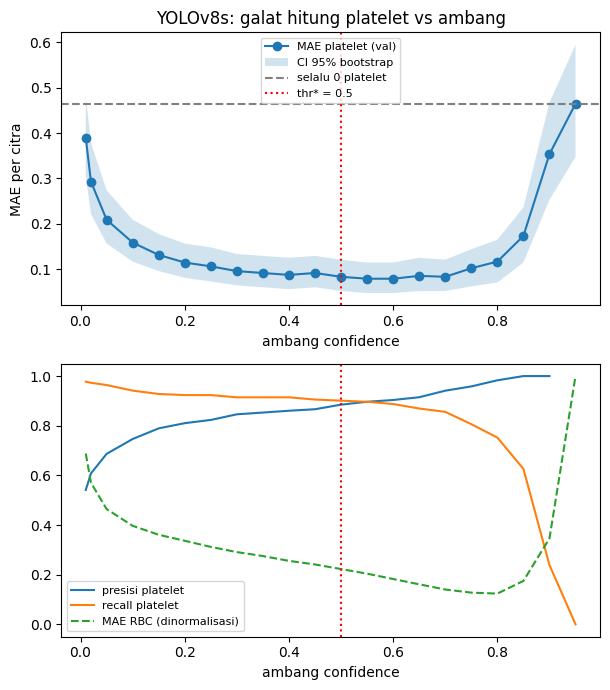

thr  mae_WBC  mae_RBC  mae_Platelets  prec_Platelets  \
YOLOv8s 0   0.01    0.607    7.247          0.389           0.541   
        1   0.02    0.387    6.006          0.293           0.608   
        2   0.05    0.209    4.891          0.209           0.687   
        3   0.10    0.123    4.180          0.159           0.746   
        4   0.15    0.092    3.799          0.132           0.789   
        5   0.20    0.075    3.544          0.115           0.810   
        6   0.25    0.063    3.285          0.107           0.823   
        7   0.30    0.059    3.065          0.096           0.846   
        8   0.35    0.046    2.895          0.092           0.853   
        9   0.40    0.040    2.692          0.088           0.860   
        10  0.45    0.033    2.540          0.092           0.866   
        11  0.50    0.027    2.345          0.084           0.885   
        12  0.55    0.019    2.149          0.079           0.896   
        13  0.60    0.015    1.923          0.079           0.904   
        14  0.65    0.015    1.697          0.086           0.915   
        15  0.70    0.013    1.477          0.084           0.941   
        16  0.75    0.008    1.345          0.103           0.958   
        17  0.80    0.017    1.303          0.117           0.983   
        18  0.85    0.067    1.841          0.174           1.000   
        19  0.90    0.272    3.642          0.354           1.000   
        20  0.95    0.956   10.533          0.464             NaN   

            rec_Platelets  f1_Platelets  mae_Platelets_sd_antar_seed  
YOLOv8s 0           0.977         0.695                        0.107  
        1           0.973         0.748                        0.047  
        2           0.964         0.802                        0.024  
        3           0.941         0.833                        0.000  
        4           0.928         0.853                        0.009  
        5           0.923         0.863                        0.003  
        6           0.923         0.871                        0.003  
        7           0.914         0.879                        0.000  
        8           0.914         0.883                        0.000  
        9           0.914         0.886                        0.000  
        10          0.905         0.885                        0.000  
        11          0.901         0.893                        0.000  
        12          0.896         0.896                        0.000  
        13          0.887         0.895                        0.006  
        14          0.869         0.891                        0.003  
        15          0.856         0.896                        0.006  
        16          0.806         0.875                        0.009  
        17          0.752         0.852                        0.006  
        18          0.626         0.770                        0.015  
        19          0.239         0.384                        0.021  
        20          0.000           NaN                        0.000

In [26]:
GRID = es.default_grid()
CURVES, SEL = {}, {}
for m, d in ME.items():
    ev = list(d.values())
    CURVES[m] = es.threshold_curve(ev, GRID)
    SEL[m] = es.select_threshold(ev, GRID, B=1000, seed=0)
    CURVES[m].to_csv(OUT / f"val_ablasi_ambang_{m}.csv", index=False)
    s = SEL[m]
    print(f"{m}: thr* = {s['thr_star']}  (argmin murni {s['thr_argmin']}; plateau {s['plateau'][0]}-{s['plateau'][-1]}; "
          f"SE {s['se_at_argmin']:.3f}; MAE val di thr* {s['mae_val_at_thr_star']:.3f}; selalu-0 {s['mae_val_selalu0']:.3f})")
    print("   frekuensi argmin pada resampel:", {k: round(v, 2) for k, v in s["argmin_freq_bootstrap"].items()})
    if s["thr_star"] in (GRID[0], GRID[-1]):
        print(f"   PERINGATAN: thr* ada di tepi grid ({s['thr_star']}). Optimum mungkin di luar grid atau kurva monoton; "
              "perluas GRID SEBELUM membekukan, tulis alasannya, dan jangan menyentuh test.")

fig, axes = plt.subplots(2, len(ME), figsize=(6.2 * len(ME), 7), squeeze=False)
for j, m in enumerate(ME):
    c, s = CURVES[m], SEL[m]
    ax = axes[0, j]
    ax.plot(c.thr, s["mae_val"], "o-", label="MAE platelet (val)")
    ax.fill_between(GRID, s["ci_lo"], s["ci_hi"], alpha=0.2, label="CI 95% bootstrap")
    ax.axhline(s["mae_val_selalu0"], color="gray", ls="--", label="selalu 0 platelet")
    ax.axvline(s["thr_star"], color="red", ls=":", label=f"thr* = {s['thr_star']}")
    ax.set_title(f"{m}: galat hitung platelet vs ambang"); ax.set_xlabel("ambang confidence"); ax.set_ylabel("MAE per citra"); ax.legend(fontsize=8)
    ax = axes[1, j]
    ax.plot(c.thr, c.prec_Platelets, label="presisi platelet"); ax.plot(c.thr, c.rec_Platelets, label="recall platelet")
    ax.plot(c.thr, c.mae_RBC / max(c.mae_RBC.max(), 1e-9), "--", label="MAE RBC (dinormalisasi)")
    ax.axvline(s["thr_star"], color="red", ls=":"); ax.set_xlabel("ambang confidence"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "val_ablasi_ambang.png", dpi=150); plt.show()
display(pd.concat({m: CURVES[m][["thr", "mae_WBC", "mae_RBC", "mae_Platelets", "prec_Platelets", "rec_Platelets", "f1_Platelets",
                                  "mae_Platelets_sd_antar_seed"]] for m in CURVES}).round(3))

In [27]:
# Bekukan ambang (satu kali). Berkas ini satu-satunya sumber ambang untuk test. Menolak menimpa tanpa force=True.
FROZEN = OUT / "thresholds_val.json"
for m in ME:
    try:
        es.freeze_thresholds(FROZEN, m, SEL[m], meta={"split_dipakai": "val", "runs": list(ME[m])})
    except FileExistsError as e:
        print("sudah dibekukan:", m, "->", es.load_frozen(FROZEN, m))
Path("logs").mkdir(exist_ok=True); (Path("logs") / "anggota4_thresholds_val.json").write_text(FROZEN.read_text())
THR = {m: es.load_frozen(FROZEN, m) for m in ME}
print("Ambang beku:", THR)

Ambang beku: {'YOLOv8s': 0.5}


## 8. Analisis kesalahan, Grad-CAM, efisiensi (val, pada ambang beku)


===== YOLOv8s (y8s_img640_s123) thr=0.5 =====
{'TP': 3474, 'FP': 659, 'FN': 94}


kelas                WBC   RBC  Platelets
kind subtype                             
FN   lokalisasi        0     4          0
     salah_kelas       0     1          0
     skor_rendah       0    70         11
     terlewat          0     1          0
     tumpang_tindih    0     7          0
FP   duplikat          0    12          0
     lainnya           1     1          0
     latar_belakang    5   462         13
     lokalisasi        0   163          0
     salah_kelas       2     0          0
TP   benar           243  3131        100

kind,FP,FN,TP
subtype,latar_belakang,skor_rendah,benar
sumber,,,
256x256,1,0,0
360x363,8,4,59
575x575,1,2,2
640x480,3,5,39


kind,FN,FP,TP
ukuran,,,
kecil,5,12,46
sedang,6,1,54


Frekuensi atribut data (platelet):


,jenis,n,kecil,bertumpuk,tepi,tanpa_atribut_otomatis
0,FP,13,12,4,10,0
1,FN,11,5,2,2,5


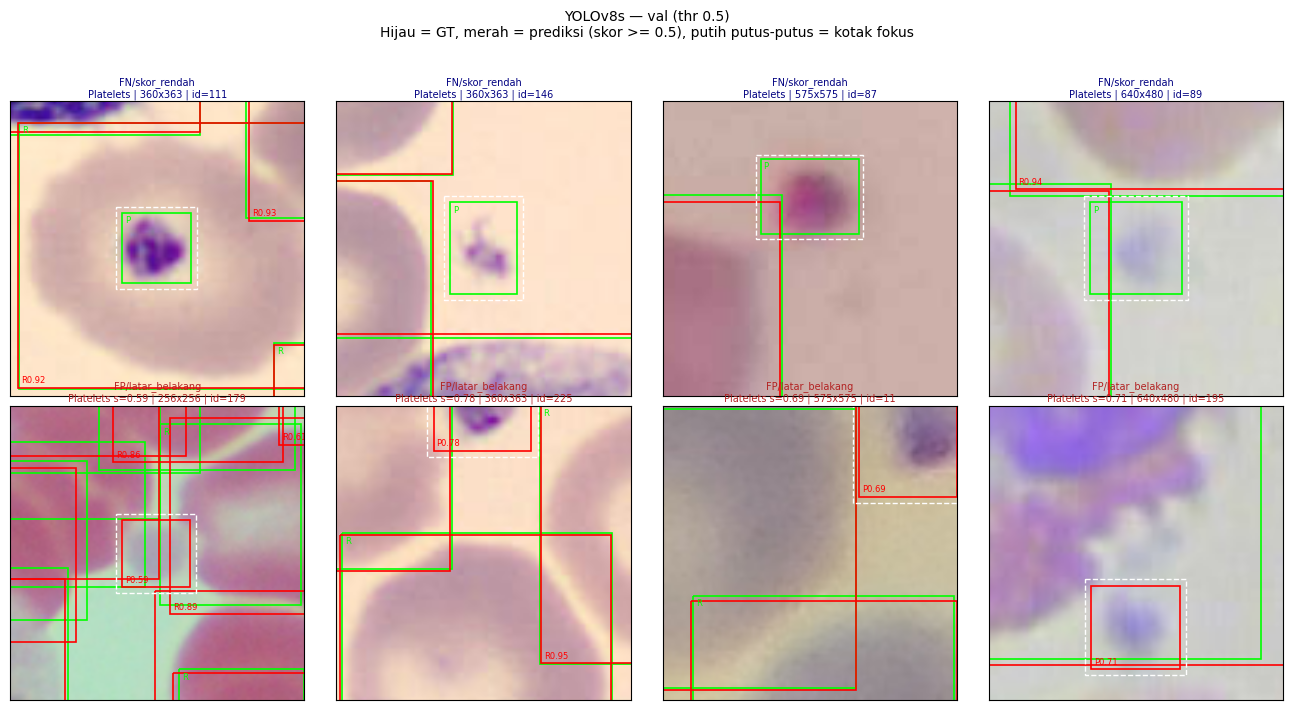

In [28]:
# 8a. Taksonomi FP/FN + atribut data + galeri (>= 8 contoh) per model, run utama (seed pertama)
ERR = {}
for m in ME:
    me = ME[m][first[m]]
    errs = ea.add_data_attributes(ea.classify_errors(me, THR[m]), gv)
    ERR[m] = errs
    tabs = ea.error_tables(errs)
    print(f"\n===== {m} ({first[m]}) thr={THR[m]} =====")
    print(errs.kind.value_counts().to_dict())
    display(tabs["per_kelas"]); display(tabs["platelet_per_sumber"]); display(tabs["platelet_per_ukuran"])
    print("Frekuensi atribut data (platelet):"); display(ea.category_frequency(errs, 3))
    sel = ea.select_gallery(errs, cats=(3,), min_total=8)
    if len(sel) < 8:
        print(f"Hanya {len(sel)} kesalahan platelet; galeri ditambah kelas lain agar >= 8")
        sel = ea.select_gallery(errs, cats=(1, 2, 3), min_total=8)
    png, sel = ea.draw_gallery(me, sel, THR[m], DATA, OUT / f"val_galeri_{m}.png", title=f"{m} — val (thr {THR[m]})")
    plt.show()
    errs.to_csv(OUT / f"val_kesalahan_{m}.csv", index=False)     # kolom 'kategori_manual' untuk diisi tim
    sel.to_csv(OUT / f"val_galeri_contoh_{m}.csv", index=False)

YOLOv8s -> kasus: {'benar': 4, 'salah': 4}


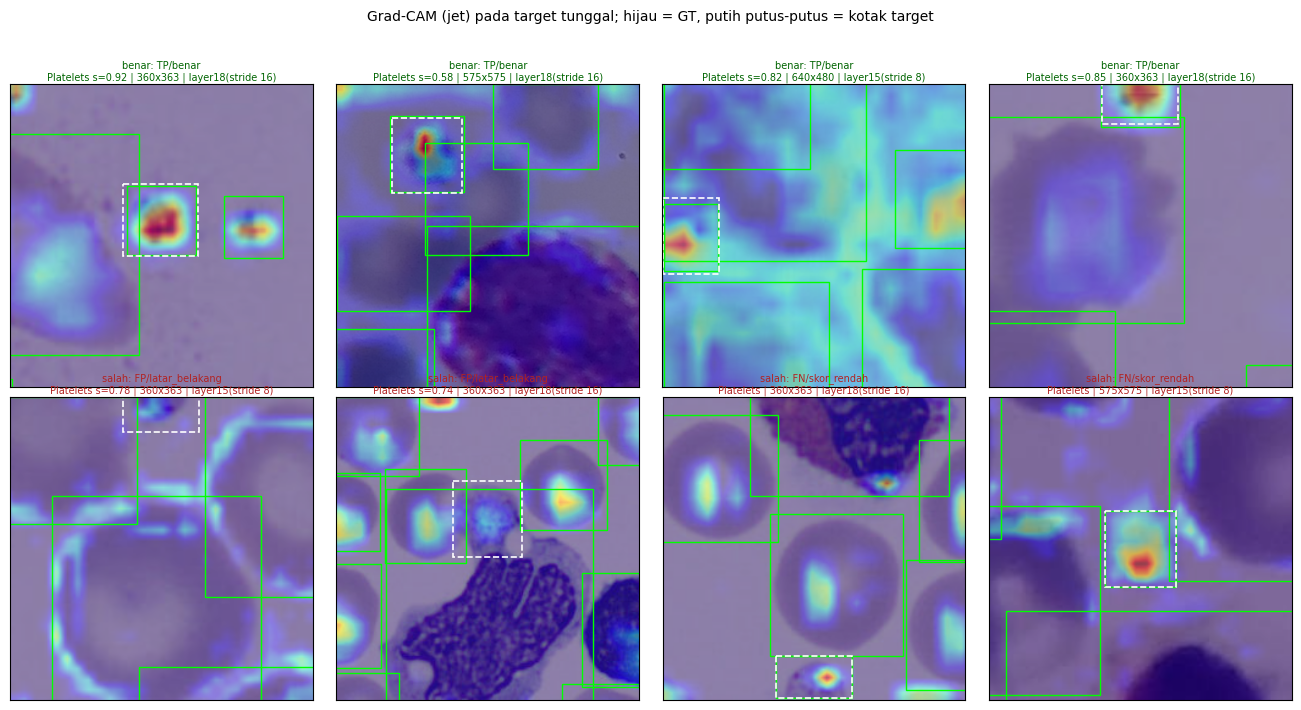

,image_id,grup,kind,subtype,sumber,level,iou_target,prob_atau_skor,logit,approx,cam_massa_dalam_kotak
0,206,benar,TP,benar,360x363,layer18(stride 16),0.984,0.911,2.321,False,0.047
1,144,benar,TP,benar,575x575,layer18(stride 16),0.998,0.573,0.296,False,0.080
2,74,benar,TP,benar,640x480,layer15(stride 8),0.992,0.812,1.465,False,0.006
3,111,benar,TP,benar,360x363,layer18(stride 16),0.978,0.827,1.564,False,0.033
4,225,salah,FP,latar_belakang,360x363,layer15(stride 8),0.948,0.777,1.247,False,0.006
5,107,salah,FP,latar_belakang,360x363,layer18(stride 16),0.987,0.751,1.103,False,0.021
6,47,salah,FN,skor_rendah,360x363,layer18(stride 16),0.512,0.003,-5.981,False,0.024
7,102,salah,FN,skor_rendah,575x575,layer15(stride 8),0.769,0.262,-1.034,False,0.054


In [29]:
# 8b. Grad-CAM: 4 kasus benar + 4 salah (platelet) per model. Lihat keterbatasan di docstring gradcam_det.py dan docs.
GCINFO = {}
for m, cfg in MODELS.items():
    run_id = first[m]
    cases = ea.select_gradcam_cases(ERR[m], cat=3, n_correct=4, n_wrong=4, seed=0)
    print(m, "-> kasus:", cases.grup.value_counts().to_dict())
    if cfg["kind"] == "yolo":
        mod = em.load_yolo(cfg["runs"][run_id])
        png, info = gc.run_gradcam_cases("yolo", mod, cases, gv, DATA, OUT / f"val_gradcam_{m}.png", imgsz=cfg["imgsz"])
    else:
        mod, _, _ = em.load_frcnn(cfg["runs"][run_id])
        png, info = gc.run_gradcam_cases("frcnn", mod, cases, gv, DATA, OUT / f"val_gradcam_{m}.png")
    plt.show()
    GCINFO[m] = info
    display(info.round(3))
    info.to_csv(OUT / f"val_gradcam_info_{m}.csv", index=False)
    del mod; torch.cuda.empty_cache()
# approx=True -> tidak ada kandidat IoU>=0.5; jangan tafsirkan peta itu sebagai penjelasan kotak target.

In [30]:
# 8c. Parameter dan latensi: batch 1, fp32, pemanasan, 100 citra x 3 pengulangan, GPU dicatat
EFF = {}
for m, cfg in MODELS.items():
    run_id = first[m]
    if cfg["kind"] == "yolo":
        mod = em.load_yolo(cfg["runs"][run_id])
        EFF[m] = em.bench_yolo(mod, gv, DATA, cfg["imgsz"], conf=THR[m], n=100, warmup=10, repeats=3)
    else:
        mod, _, _ = em.load_frcnn(cfg["runs"][run_id])
        EFF[m] = em.bench_frcnn(mod, gv, DATA, score_thresh=THR[m], n=100, warmup=10, repeats=3)
    del mod; torch.cuda.empty_cache()
eff = pd.DataFrame({m: {k: v for k, v in d.items() if not isinstance(v, (list, dict))} for m, d in EFF.items()}).T
display(eff)
(OUT / "val_efisiensi.json").write_text(json.dumps(EFF, indent=2, default=str))
print("GPU:", EFF[next(iter(EFF))]["gpu"], "| catatan: latensi bergantung pada GPU/sesi Colab; ukur kedua model di sesi yang sama.")

,n_images,unique_images,repeats,warmup,batch,precision,mean_ms,std_ms,median_ms,p95_ms,...,peak_mem_mb,gpu,torch,cuda,python,params,params_m,conf_inferensi,imgsz,cakupan
YOLOv8s,100,100,3,10,1,fp32,20.359399,10.416336,16.68946,39.781747,...,78.503906,Tesla T4,2.14.1+cu130,13.0,3.13.16,11136761,11.137,0.5,640,array BGR di memori -> kotak di CPU (preproces...


GPU: Tesla T4 | catatan: latensi bergantung pada GPU/sesi Colab; ukur kedua model di sesi yang sama.


In [31]:
# 8d. Catat ke log tim (logs/runs_anggota4.csv) lalu salin ke Drive
for m, d in ME.items():
    for r, me in d.items():
        s = me.summary(THR[m])
        eff_m = EFF[m] if r == first[m] else {}
        log_run("anggota4", run_id=f"eval4_{r}", model=m, purpose="ablation", ablation_factor="conf_threshold",
                factor_value=THR[m], seed=r.rsplit("_s", 1)[-1], train_split="train", val_split="val",
                imgsz_or_min_size=MODELS[m].get("imgsz", 640), pretrained="COCO",
                env=f"torch {torch.__version__}; ultralytics {ultralytics.__version__}",
                val_map50=round(s["map50"], 4), val_map50_95=round(s["map50_95"], 4),
                val_ap50_platelet=round(s["ap50_Platelets"], 4), val_mae_platelet=round(s["mae_Platelets"], 4),
                params_m=eff_m.get("params_m", ""), latency_ms=round(eff_m["mean_ms"], 2) if eff_m else "",
                status="ok", notes=f"evaluasi bersama pycocotools; thr dipilih di val ({SEL[m]['rule']}); dedup={DEDUP}")
import shutil
(OUT / "logs").mkdir(exist_ok=True)
shutil.copy("logs/runs_anggota4.csv", OUT / "logs" / "runs_anggota4.csv")
print(pd.read_csv("logs/runs_anggota4.csv").tail(len(ME) * 3)[["run_id", "model", "factor_value", "val_map50", "val_mae_platelet", "params_m", "latency_ms"]])

                  run_id    model  factor_value  val_map50  val_mae_platelet  \
0  eval4_y8s_img640_s123  YOLOv8s           0.5     0.9756            0.0837   
1   eval4_y8s_img640_s42  YOLOv8s           0.5     0.9740            0.0837   

   params_m  latency_ms  
0    11.137       20.36  
1       NaN         NaN  


## 9. EVALUASI FINAL pada test dan test_unflagged — **SEKALI per konfigurasi**
Jalankan hanya setelah tim menetapkan konfigurasi final (arsitektur, hyperparameter, seed). Prasyarat: ambang beku dari val (sel 7), `FINAL_TEST = True`, dan `CONFIRM_TEXT` diisi persis. Sel ini menolak menulis baris `(run_id, split)` yang sudah ada di `logs/final_test_results.csv`, dan **tidak** menggambar kurva ambang di test (ambang hanya dari berkas beku).

In [32]:
FINAL_TEST = False
CONFIRM_TEXT = ""      # isi: SAYA PAHAM: TEST HANYA SEKALI
FINAL_CSV = "logs/final_test_results.csv"

def run_final():
    assert FINAL_TEST and CONFIRM_TEXT == "SAYA PAHAM: TEST HANYA SEKALI", "terkunci: set FINAL_TEST dan CONFIRM_TEXT"
    assert FROZEN.exists(), "ambang beku dari val belum ada"
    for split in ["test", "test_unflagged"]:
        for m in MODELS:                      # periksa DULU agar tidak ada yang terlanjur dihitung ulang
            for r in MODELS[m]["runs"]:
                assert not es.final_test_already_done(FINAL_CSV, r, split), f"({r}, {split}) sudah tercatat: test hanya sekali"
    out = {}
    for split in ["test", "test_unflagged"]:
        gt = get_gt(split)
        print(f"\n##### {split}: {len(gt)} citra | platelet GT {int(gt.n_gt[3].sum())} | MAE selalu-0 platelet {es.always_zero_mae(gt):.3f}")
        display(gt.summary())
        mes = {m: {r: es.ModelEval(gt, get_preds(split, m, r), name=r) for r in MODELS[m]["runs"]} for m in MODELS}
        for m, d in mes.items():
            ev = list(d.values())
            for r, me in d.items():
                s = me.summary(THR[m])
                bres, _ = es.bootstrap({r: me}, gt, THR[m], B=1000, seed=2024, metrics=("ap50_Platelets", "mae_Platelets"), pairs=False)
                g = lambda k: bres[bres.metrik == k].iloc[0]
                ci = f"AP50 {es.fmt_ci(g('ap50_Platelets').ci_lo, g('ap50_Platelets').ci_hi)}; MAE {es.fmt_ci(g('mae_Platelets').ci_lo, g('mae_Platelets').ci_hi)}"
                es.append_final_test_row(FINAL_CSV, {
                    "run_id": r, "test_split": split, "map50": round(s["map50"], 4), "map50_95": round(s["map50_95"], 4),
                    "ap50_platelet": round(s["ap50_Platelets"], 4), "mae_wbc": round(s["mae_WBC"], 4),
                    "mae_rbc": round(s["mae_RBC"], 4), "mae_platelet": round(s["mae_Platelets"], 4),
                    "bootstrap_ci_platelet": ci, "date": time.strftime("%Y-%m-%d"),
                    "notes": f"thr={THR[m]} (beku di val); dedup={DEDUP}; bootstrap citra B=1000 CI95 persentil; satu kali pakai"})
        res, _ = es.bootstrap({m: list(d.values()) for m, d in mes.items()}, gt, THR, B=1000, seed=2024)
        res.to_csv(OUT / f"final_{split}_bootstrap_seedmean.csv", index=False); display(res.round(4))
        for m, d in mes.items():
            ps = d[first[m]].per_source(THR[m]); ps.to_csv(OUT / f"final_{split}_per_source_{m}.csv", index=False)
            display(ps[["sumber", "n_citra", "n_gt_Platelets", "ap50_Platelets", "mae_Platelets", "mae_Platelets_selalu0", "andal"]].round(3))
            errs = ea.add_data_attributes(ea.classify_errors(d[first[m]], THR[m]), gt)
            errs.to_csv(OUT / f"final_{split}_kesalahan_{m}.csv", index=False)
            sel = ea.select_gallery(errs, cats=(3,), min_total=8)
            if len(sel) >= 1:
                ea.draw_gallery(d[first[m]], sel, THR[m], DATA, OUT / f"final_{split}_galeri_{m}.png", title=f"{m} — {split}"); plt.show()
        out[split] = mes
    shutil.copy(FINAL_CSV, OUT / "logs" / "final_test_results.csv")
    return out

# FINAL = run_final()      # <- aktifkan HANYA saat konfigurasi final sudah disepakati
print(pd.read_csv(FINAL_CSV))

Empty DataFrame
Columns: [run_id, test_split, map50, map50_95, ap50_platelet, mae_wbc, mae_rbc, mae_platelet, bootstrap_ci_platelet, date, notes]
Index: []


## 10. Simpan ke repositori tim
Salin `scripts/eval_shared.py`, `error_analysis.py`, `eval_models.py`, `gradcam_det.py`, `logs/runs_anggota4.csv`, `logs/final_test_results.csv`, `logs/anggota4_thresholds_val.json`, dan folder `OUT` (gambar, CSV) ke repo (commit). Bobot dan prediksi besar cukup tautan Drive.